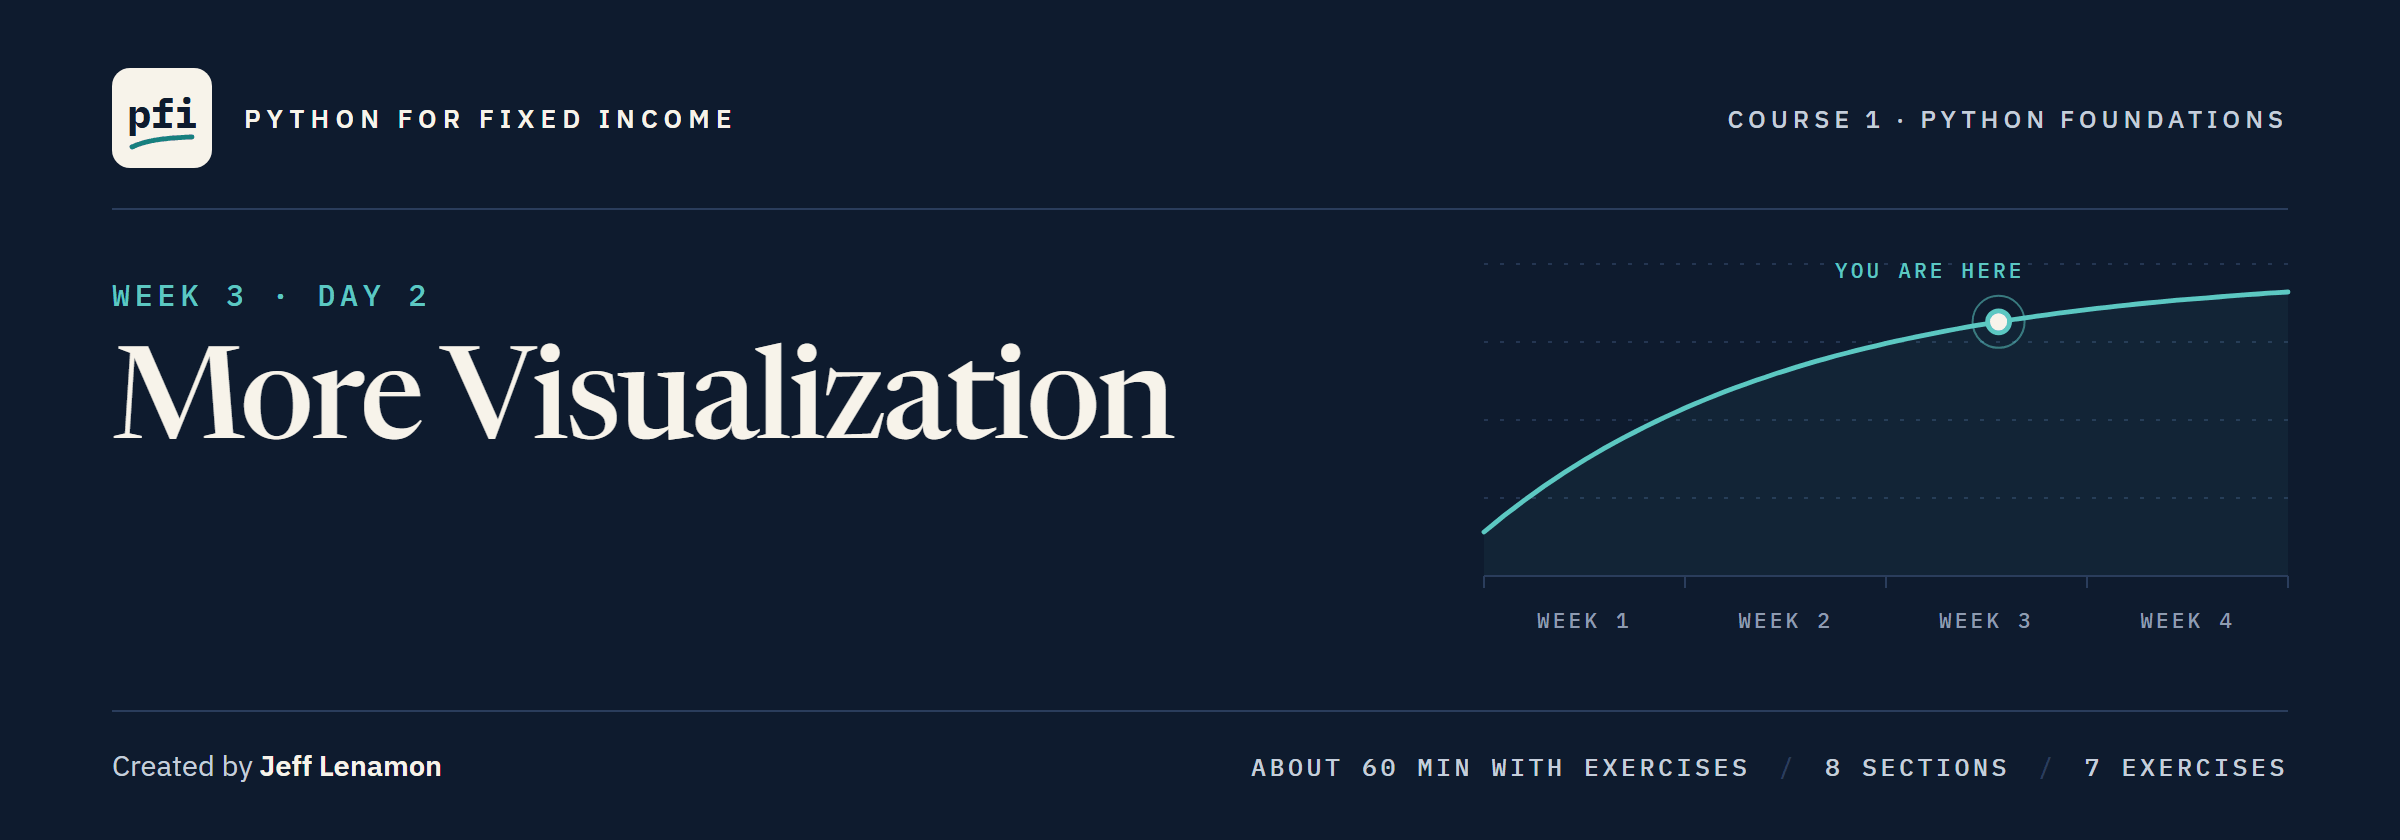

# More Visualization

Week 3, Day 2. A line through a scatter with its slope, the bonds behind every shape, charts that answer the mouse, and a chart finished for the meeting.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day2/12_visualization_more.ipynb)

## The Desk Lead's Note

> Your seven charts went round the desk. Three asks before the meeting. Put a line through a scatter and give me its slope, in units. Show me how many bonds stand behind each shape. Then make the charts meeting-ready: our colours, numbers I can read, the bond everyone asks about marked, and a file for the slide. No chart says more than the data.

The issuers are invented; a line fitted here summarizes this file and forecasts nothing.

**Three asks, in order: a slope, the bonds, a chart fit to leave the desk.**

## Your Route Through Day 2

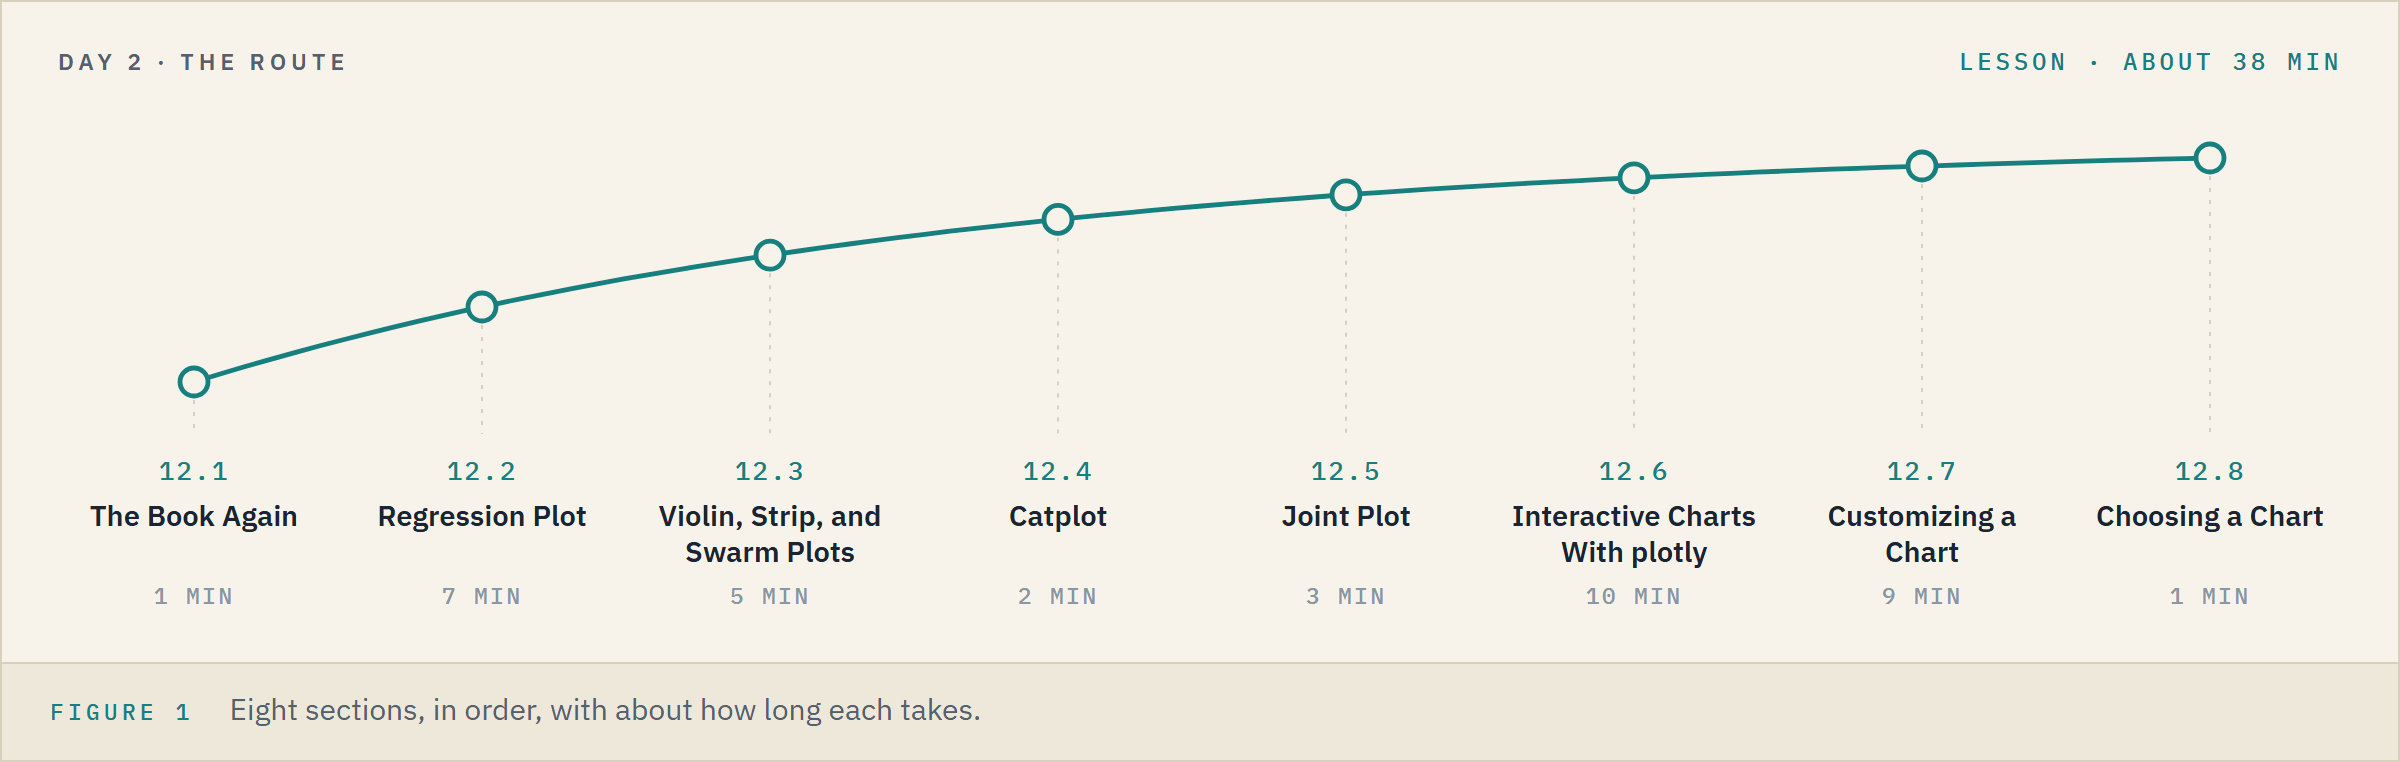

**Time.** About 38 minutes for the lesson, then about 21 for the seven exercises.

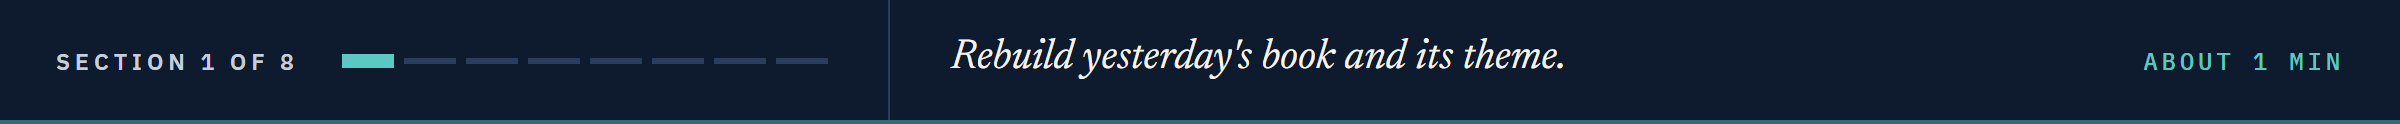

## 12.1 The Book Again

### Yesterday's Book in One Cell

Q. Rebuild Visualization's `book`, its credit order, and its house theme.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Visualization's house theme: greens and greys on a light grid, a dark median in a box
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'],
              rc={'boxplot.medianprops.color': '#1E4D3A'})
# the repo's data folder on your machine; in Colab, GitHub
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
book = pd.merge(holdings, ratings, on='rating')
bucket_order = ratings.sort_values('score')['bucket'].unique().tolist()
print(book.shape)

(200, 22)


**Same table, same credit order, same greens: today adds a slope, the bonds, and the finish.**

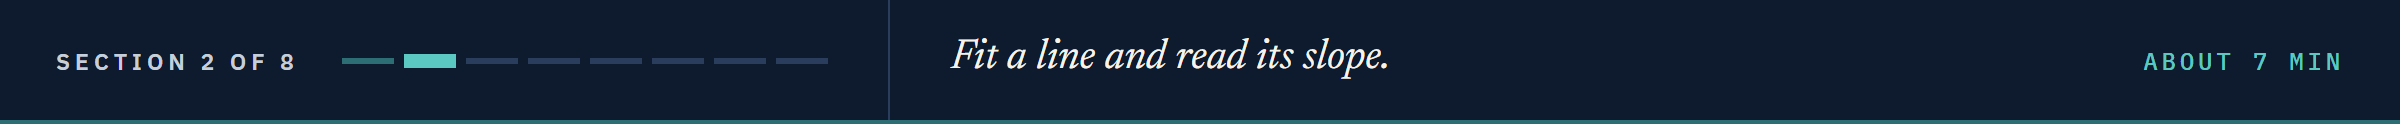

## 12.2 Regression Plot

A **regression line** is `y = intercept + slope * x`.
The **slope** is the change in y per unit of x, in y's unit per x's unit; the **intercept** is the line's height where x is zero.

### A Line Through Coupon and Yield

Q. Coupon and yield correlate at 0.74 in Visualization's heatmap. Which straight line fits yield, given coupon?

In [2]:
# np.polyfit(): the x column, the y column, and deg=1 for a straight line
# it returns the slope, then the intercept; slope, intercept = takes both, as fig, ax = does
slope, intercept = np.polyfit(book['coupon'], book['yield_pct'], deg=1)
print('Slope:', round(slope, 2), 'points of yield per point of coupon')
print('Intercept:', round(intercept, 2), 'percent')
print('The line at 5 and 8 percent coupons:',
      round(intercept + slope * 5, 2), round(intercept + slope * 8, 2))
print('Lowest coupon in the book:', book['coupon'].min())

Slope: 0.88 points of yield per point of coupon
Intercept: 0.85 percent
The line at 5 and 8 percent coupons: 5.26 7.91
Lowest coupon in the book: 3.25


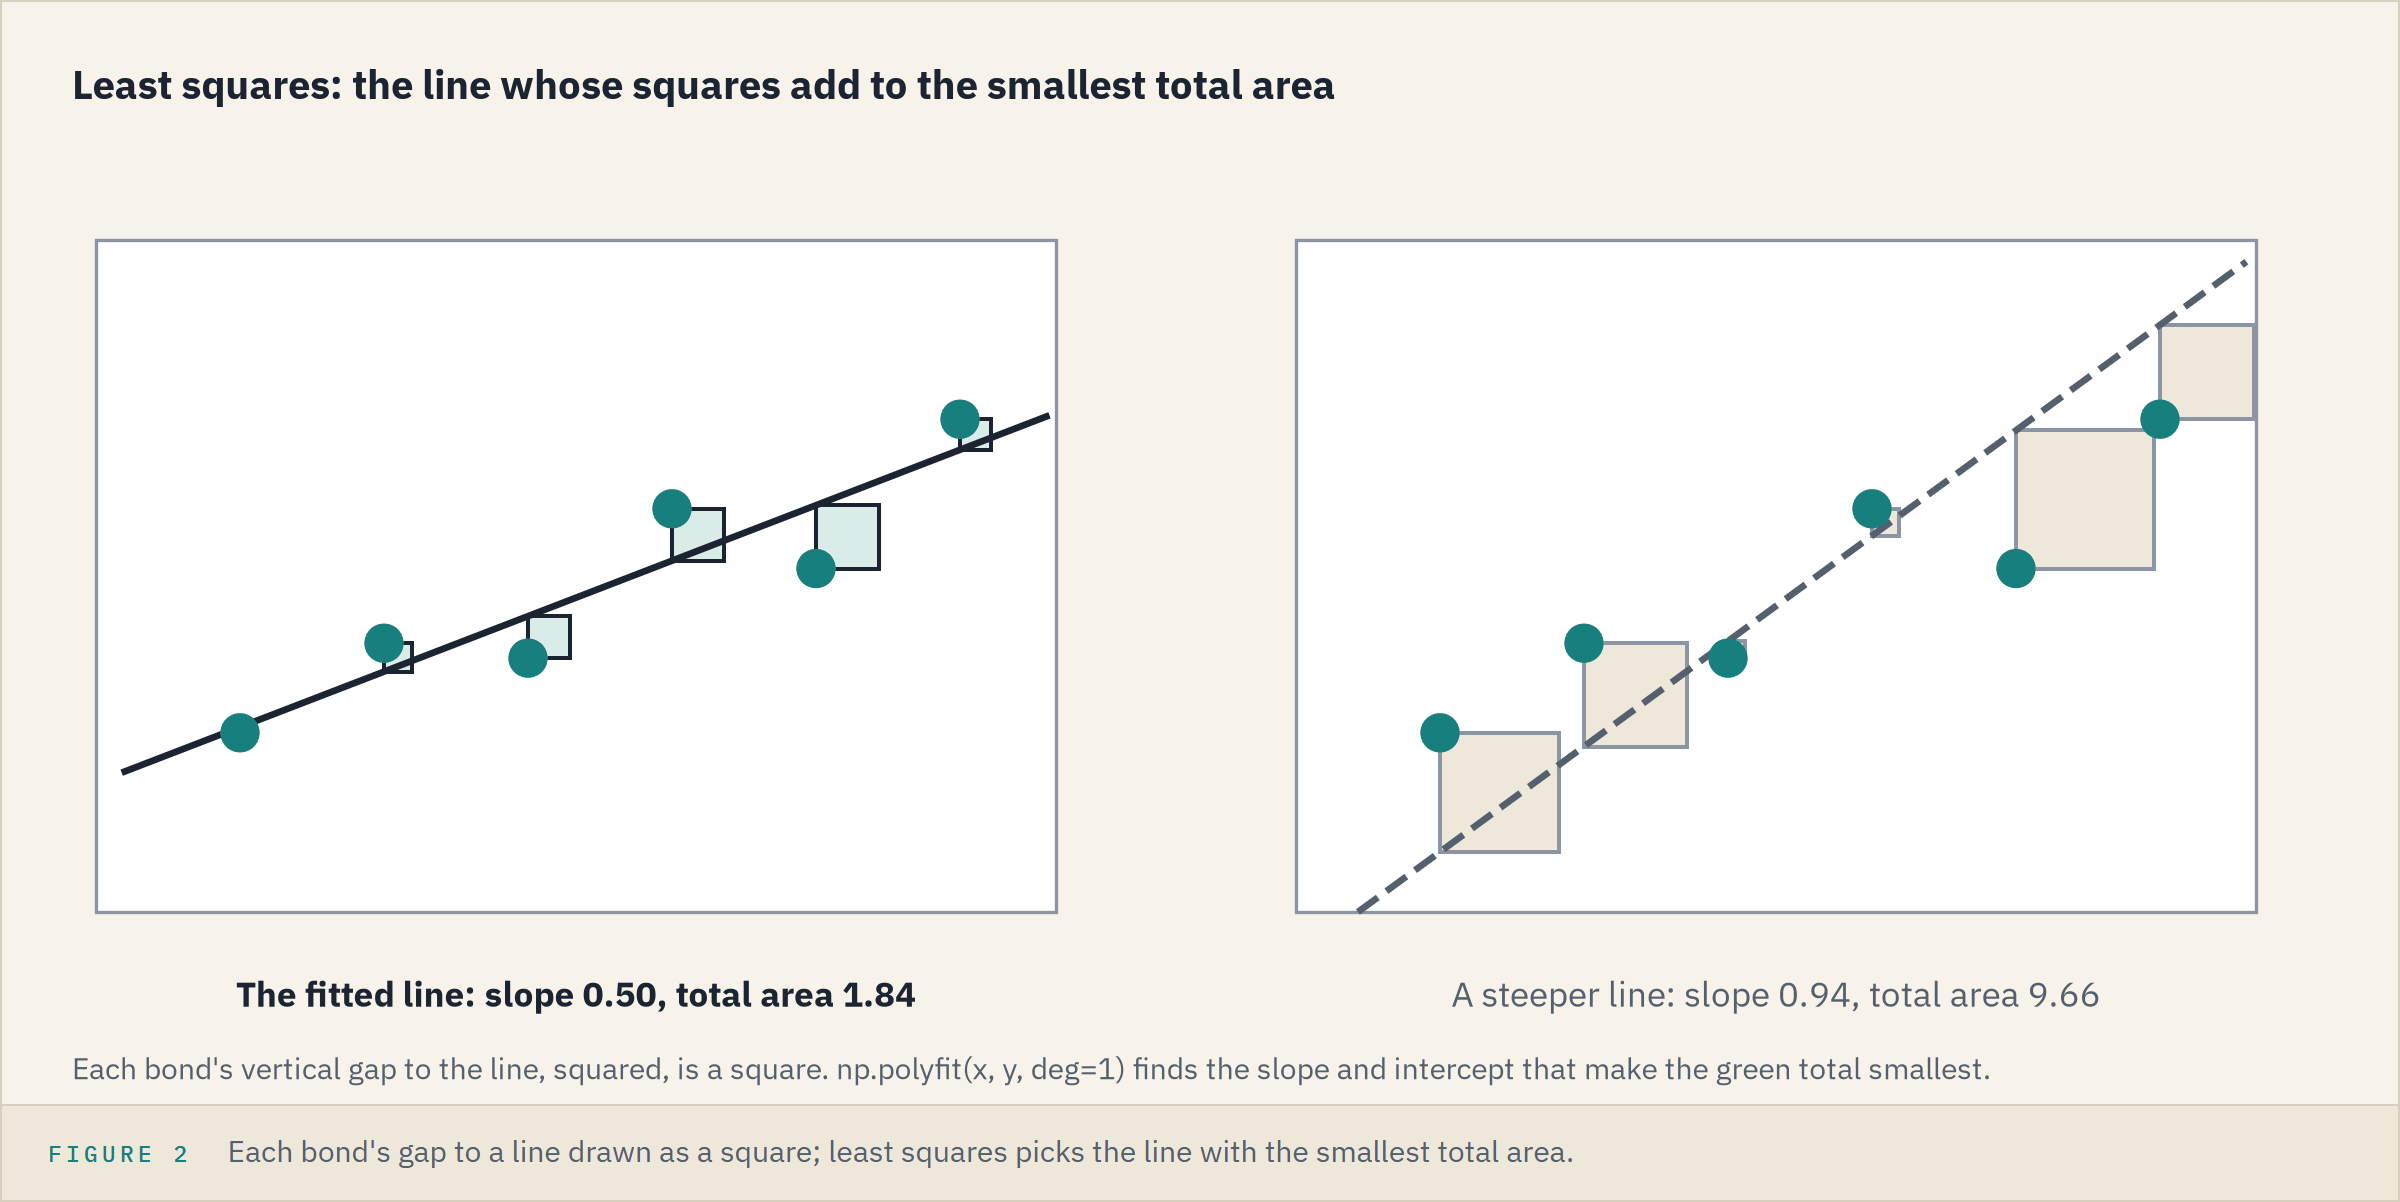

One more point of coupon goes with 0.88 more of yield, so 5.26 and 7.91 sit 3 x 0.88 apart: points on the line, not any bond's yield.
The intercept, 0.85, is the height at a zero coupon, far left of the lowest bond's 3.25.

### Leave Out the Degree

In [3]:
# the same fit, with deg= left out
slope, intercept = np.polyfit(book['coupon'], book['yield_pct'])

TypeError: polyfit() missing 1 required positional argument: 'deg'

A `TypeError`, read from the bottom as in week 1's Day 3: NumPy will not guess the degree.
The failed line stored nothing, so `slope` and `intercept` keep their values.

### The Line Over the Bonds

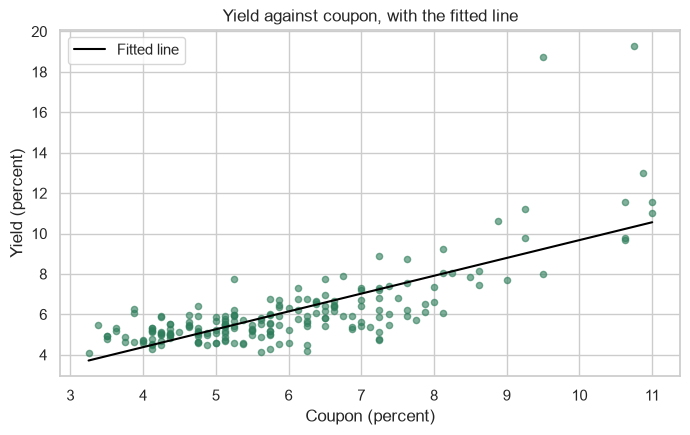

In [4]:
# s= sets each dot's size; alpha= how solid it is, from 0 (invisible) to 1
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(book['coupon'], book['yield_pct'], s=20, alpha=0.6)
# a straight line needs two ends: the lowest and highest coupon, as one array
line_x = np.array([book['coupon'].min(), book['coupon'].max()])
ax.plot(line_x, intercept + slope * line_x, color='black', label='Fitted line')
ax.legend()
ax.set_title('Yield against coupon, with the fitted line')
ax.set_xlabel('Coupon (percent)')
ax.set_ylabel('Yield (percent)')
plt.show()

Two bonds above 18 percent sit far over the line; squaring each gap gives a far bond a large say.

### The Line and Its Band From `sns.regplot`

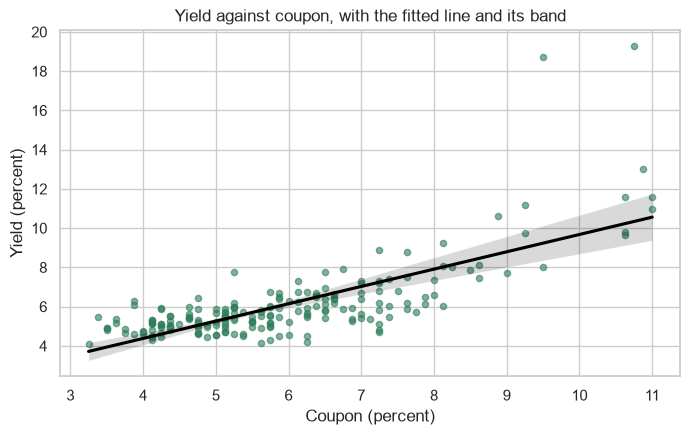

R squared: 0.55


In [5]:
# regplot(): the dots, the fitted line, and a band; seed=0 fixes the band's random redraws
# scatter_kws= and line_kws= are dicts of settings handed to the dots and to the line
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=book, x='coupon', y='yield_pct', seed=0,
            scatter_kws={'s': 20, 'alpha': 0.6}, line_kws={'color': 'black'}, ax=ax)
ax.set_title('Yield against coupon, with the fitted line and its band')
ax.set_xlabel('Coupon (percent)')
ax.set_ylabel('Yield (percent)')
plt.show()
# R squared: the correlation, squared
print('R squared:', round(book['coupon'].corr(book['yield_pct']) ** 2, 2))

The band, built like Visualization's from 1,000 random redraws, is narrow where the bonds crowd and wide at high coupons; it is about the line, not the bonds.
**R squared**, from 0 to 1, is the share of the variation in y that a straight least-squares line on x explains: 55 percent of yield's here.

**Excel side by side.** Coupon is column G and yield column L.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Slope</td><td align="left"><code>np.polyfit(x, y, deg=1)[0]</code>, 0.88</td><td align="left"><code>=SLOPE(L2:L201, G2:G201)</code></td></tr>
<tr><td align="left">Intercept</td><td align="left"><code>np.polyfit(x, y, deg=1)[1]</code>, 0.85</td><td align="left"><code>=INTERCEPT(L2:L201, G2:G201)</code></td></tr>
<tr><td align="left">R squared</td><td align="left"><code>x.corr(y) ** 2</code>, 0.55</td><td align="left"><code>=RSQ(L2:L201, G2:G201)</code></td></tr>
<tr><td align="left">The line on the chart</td><td align="left"><code>sns.regplot()</code></td><td align="left">Chart Elements, Trendline, Linear</td></tr>
</table>
<br clear="left">

Excel takes y first and NumPy x first; Excel's trendline draws no band.

**Slope, intercept, R squared, each with its unit: print them beside any line.**

### Predict 1: A Line Through a Cloud

**Predict 1**

Q. The Visualization notebook put duration and OAS at -0.11. What slope does `np.polyfit(book['duration'], book['oas'], deg=1)` give?

A) Positive: longer bonds carry more spread.
B) Negative, and small against OAS's range of 19 to 1,551 bp.
C) Exactly zero.

Slope: -6.15 bp per year  R squared: 0.01


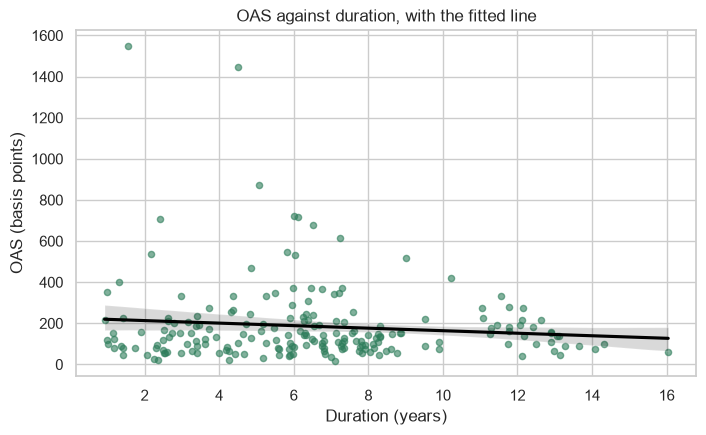

In [6]:
# OAS on duration: the slope is in basis points per year
duration_slope, duration_intercept = np.polyfit(book['duration'], book['oas'], deg=1)
print('Slope:', round(duration_slope, 2), 'bp per year  R squared:',
      round(book['duration'].corr(book['oas']) ** 2, 2))
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=book, x='duration', y='oas', seed=0,
            scatter_kws={'s': 20, 'alpha': 0.6}, line_kws={'color': 'black'}, ax=ax)
ax.set_title('OAS against duration, with the fitted line')
ax.set_xlabel('Duration (years)')
ax.set_ylabel('OAS (basis points)')
plt.show()

B: the slope is -6.15 bp per year, with the correlation's sign, and nearly flat at an R squared of 0.01: a line fits any cloud.

### One Line per Grade

Q. The Visualization notebook split this cloud by grade. Fit each grade on its own bonds.

Investment Grade 2.99 bp per year
High Yield -7.86 bp per year


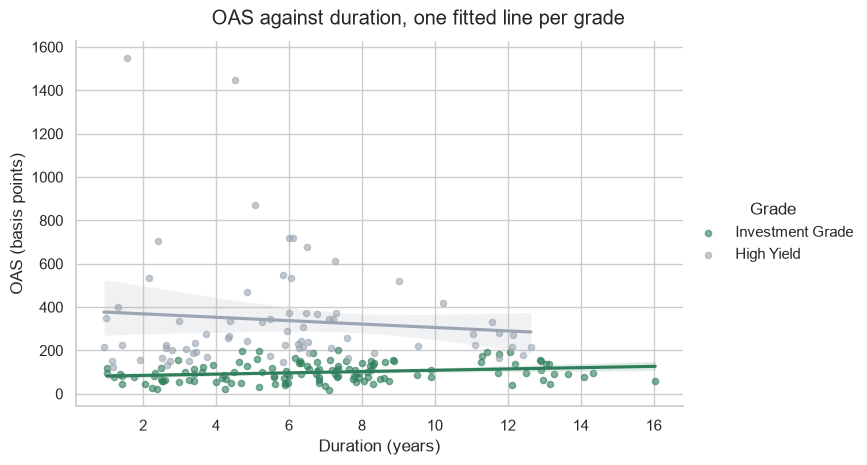

In [7]:
# each grade's slope, fitted on that grade's bonds only
for grade in ['Investment Grade', 'High Yield']:
    part = book[book['grade'] == grade]
    print(grade, round(np.polyfit(part['duration'], part['oas'], deg=1)[0], 2), 'bp per year')
# lmplot(): regplot() with hue=; it builds its own figure, as displot() does
grid = sns.lmplot(data=book, x='duration', y='oas', hue='grade', seed=0, height=4.5, aspect=1.6,
                  scatter_kws={'s': 20, 'alpha': 0.6})
grid.set_axis_labels('Duration (years)', 'OAS (basis points)')
# grid.legend is the grid's legend; set_title() names it
grid.legend.set_title('Grade')
grid.figure.suptitle('OAS against duration, one fitted line per grade', y=1.03)
plt.show()

The lines tilt opposite ways, as Visualization's 0.24 and -0.1 said, so the book's -6.15 describes neither grade.
The High Yield band is wider: fewer bonds, spread further apart.

### A Panel per Grade, No Band

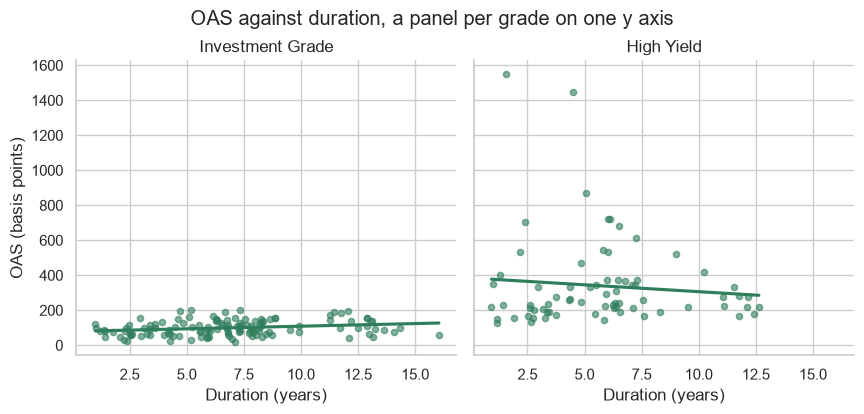

In [8]:
# col= a panel per grade; ci=None leaves the band off
grid = sns.lmplot(data=book, x='duration', y='oas', col='grade', ci=None, height=4, aspect=1.1,
                  scatter_kws={'s': 20, 'alpha': 0.6})
grid.set_axis_labels('Duration (years)', 'OAS (basis points)')
grid.set_titles('{col_name}')
grid.figure.suptitle('OAS against duration, a panel per grade on one y axis', y=1.03)
plt.show()

**A line fits any cloud, so fit each group on its own. Next, the shape of each grade under the lines.**

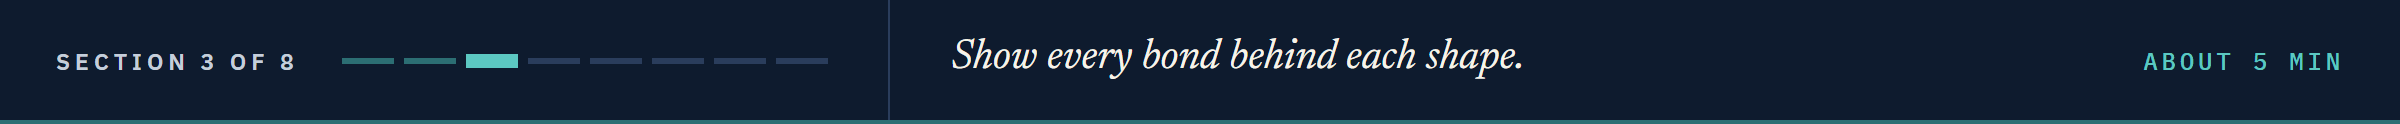

## 12.3 Violin, Strip, and Swarm Plots

A **violin plot** is a box with its shape: a smoothed histogram, mirrored, wide where the bonds crowd.

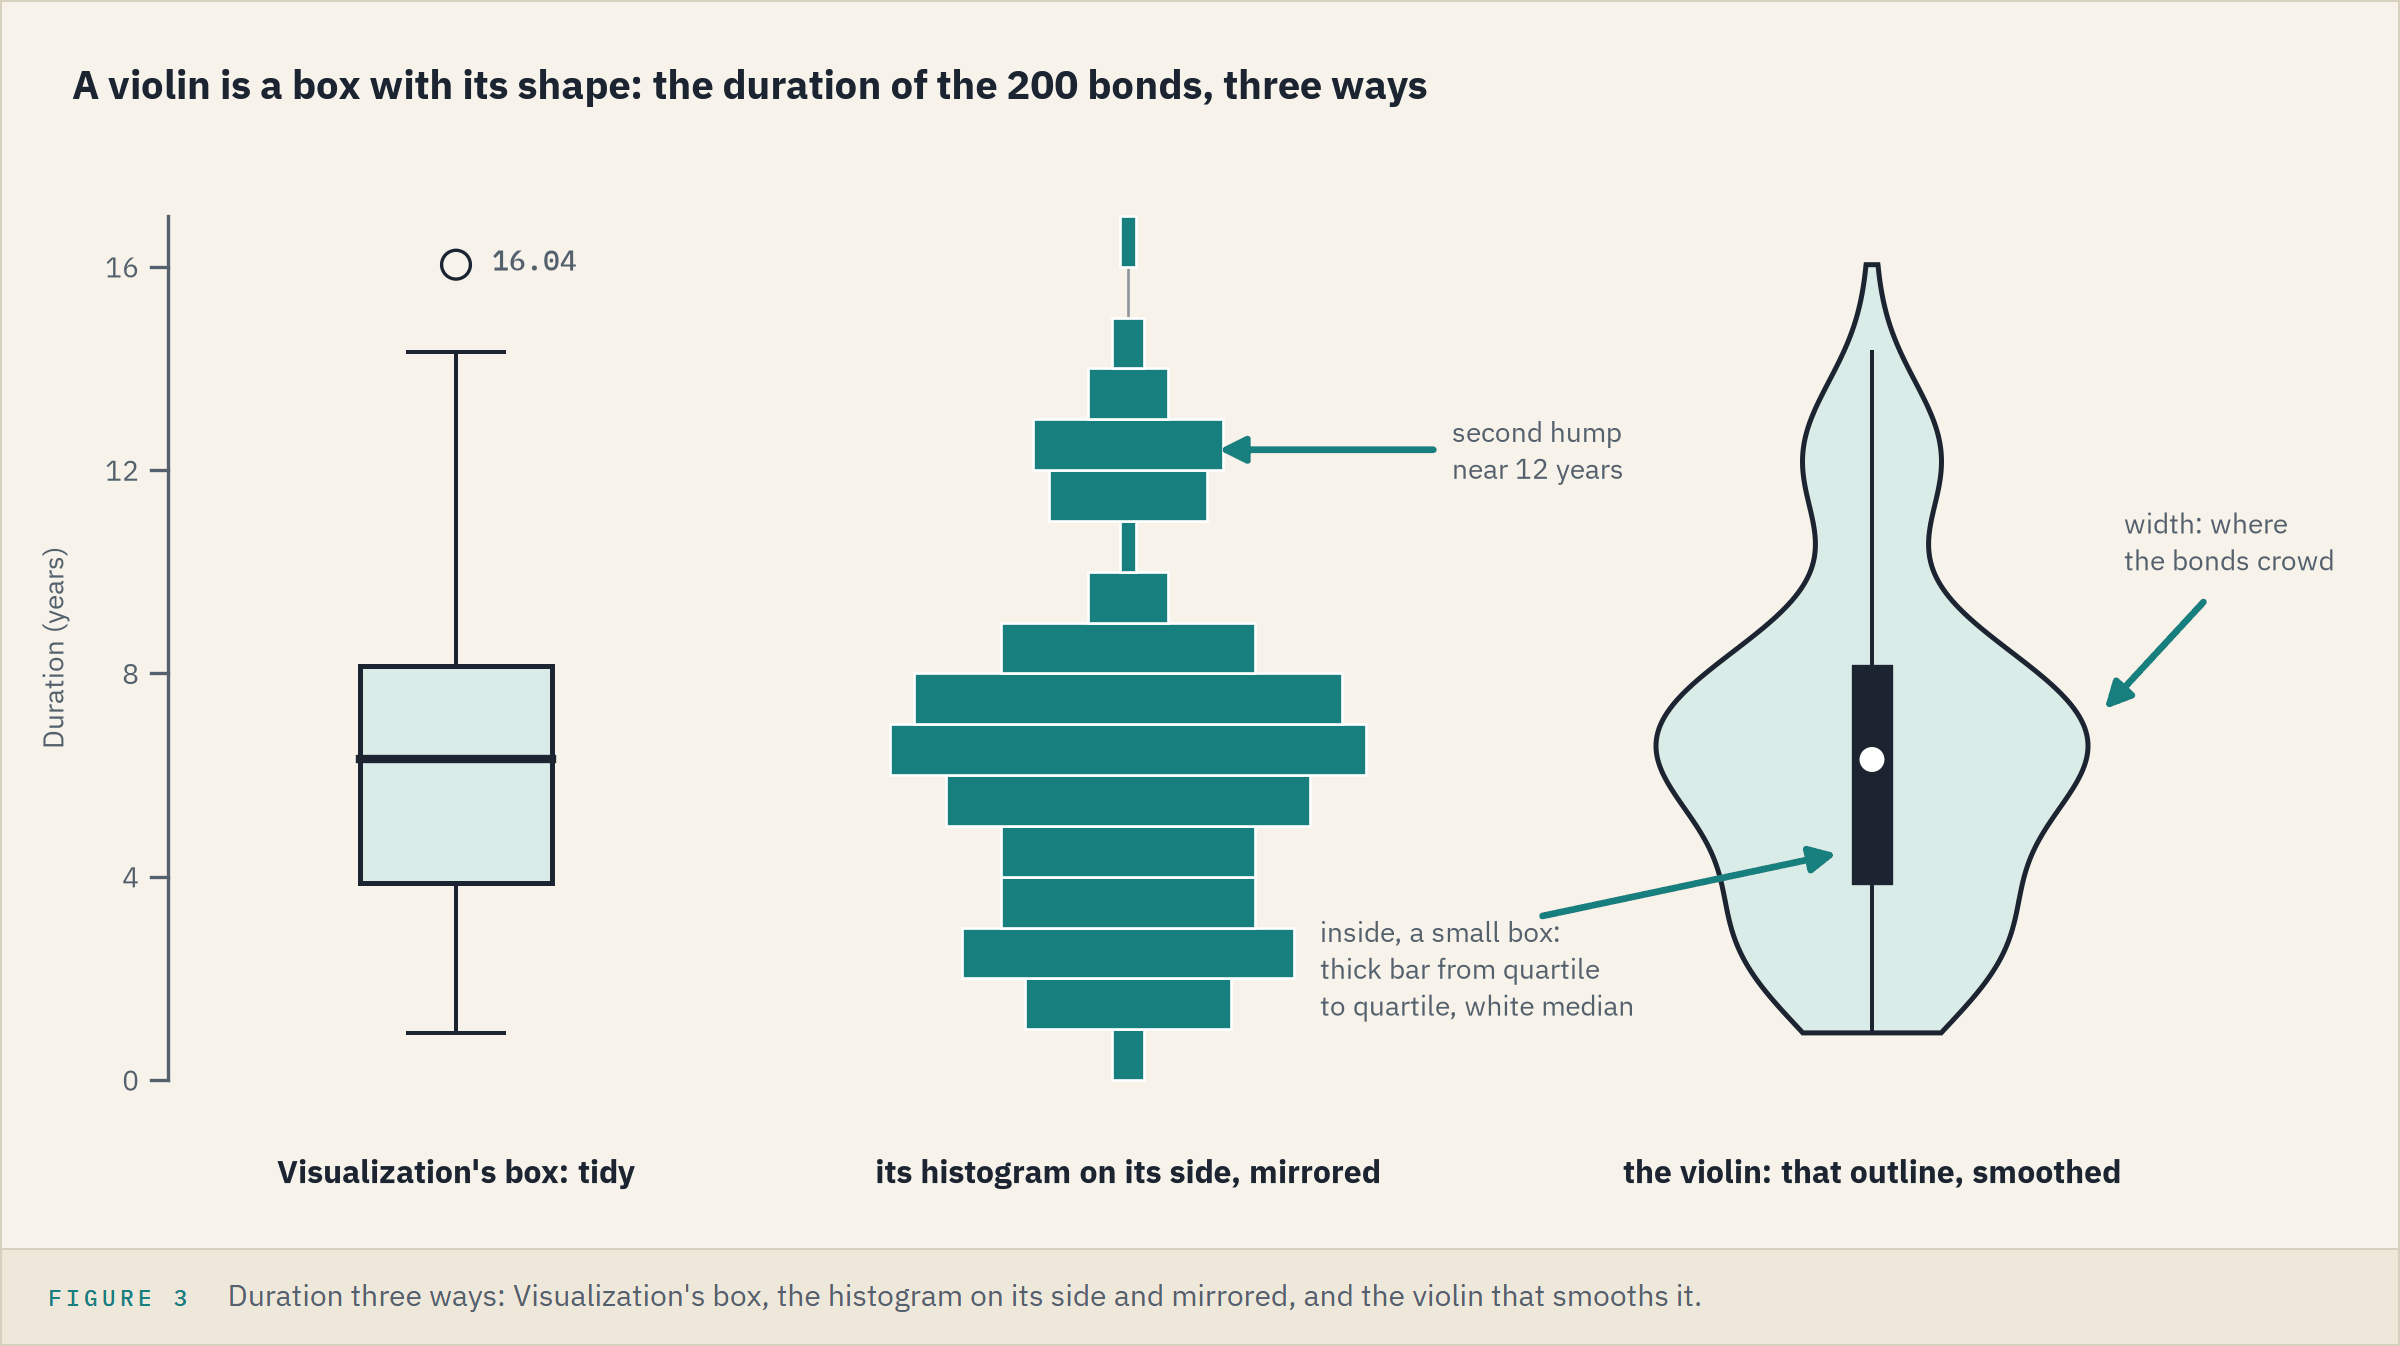

### Predict 2: Where a Violin Ends

**Predict 2**

Q. No bond's OAS is below 19 bp. Where does the bottom of the Investment Grade violin end in `sns.violinplot(data=book, x='grade', y='oas')`?

A) At 19 bp, the lowest bond.
B) At 0.
C) Below 0.

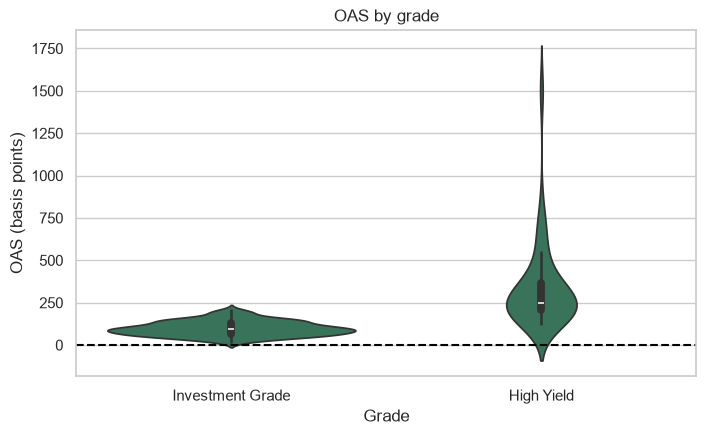

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
# violinplot(): a violin per grade; axhline(0) marks zero
sns.violinplot(data=book, x='grade', y='oas', ax=ax)
ax.axhline(0, color='black', linestyle='--')
ax.set_title('OAS by grade')
ax.set_xlabel('Grade')
ax.set_ylabel('OAS (basis points)')
plt.show()

C: both shapes cross the dashed zero, Investment Grade only just.
Smoothing spreads each bond a little both ways, and the outline runs on past the lowest and highest bond, as in Visualization's pair plot.

### Cut at the Lowest and Highest Bond

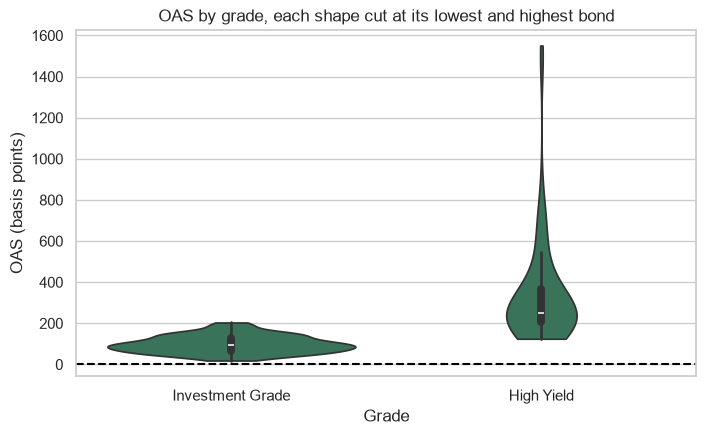

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
# cut=0 ends each shape at its lowest and highest bond
sns.violinplot(data=book, x='grade', y='oas', cut=0, ax=ax)
ax.axhline(0, color='black', linestyle='--')
ax.set_title('OAS by grade, each shape cut at its lowest and highest bond')
ax.set_xlabel('Grade')
ax.set_ylabel('OAS (basis points)')
plt.show()

Each shape now spans Visualization's ranges, 19 to 204 bp and 125 to 1,551.
Investment Grade draws nearly three times wider without three times the bonds: each violin gets the same area, `density_norm='area'`; `'count'` sizes them by bonds.

**A violin's outline is smoothing: check its ends against `min()` and `max()`, and read width as concentration, not count.**

### Every Bond, by Bucket

Q. How many bonds stand behind each bucket?

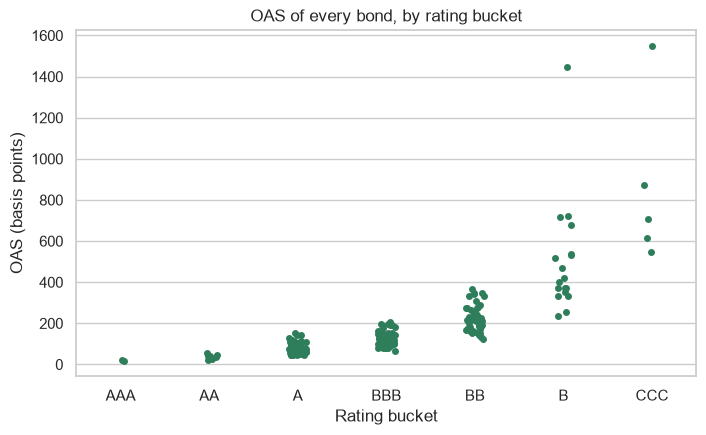

In [11]:
# stripplot(): a dot per bond, nudged sideways at random so the dots do not hide each other
# np.random.seed(0) fixes the nudges, so the chart is the same on every run
np.random.seed(0)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.stripplot(data=book, x='bucket', y='oas', order=bucket_order, ax=ax)
ax.set_title('OAS of every bond, by rating bucket')
ax.set_xlabel('Rating bucket')
ax.set_ylabel('OAS (basis points)')
plt.show()

The dots count for you: 2 at AAA and 5 at CCC, against 56, 62 and 49 in the middle, where Visualization's boxes drew AAA's 2 like BBB's 62.
The sideways nudge, **jitter**, means nothing; only height is data.

### Every Bond, Side by Side

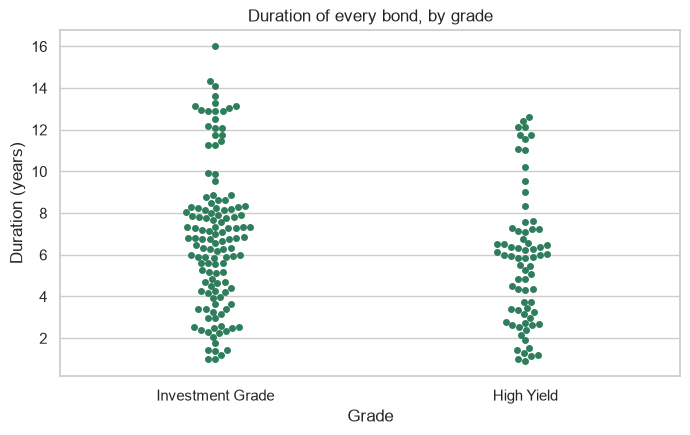

In [12]:
# swarmplot(): each dot moved just far enough to clear its neighbours, so no seed is needed
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.swarmplot(data=book, x='grade', y='duration', ax=ax)
ax.set_title('Duration of every bond, by grade')
ax.set_xlabel('Grade')
ax.set_ylabel('Duration (years)')
plt.show()

A swarm is a violin's outline built of bonds: a bulge near 12 years, 16.04 alone on top.

**Excel side by side.** OAS is column M and grade column V.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Shape of each group</td><td align="left"><code>sns.violinplot()</code></td><td align="left">no violin chart; Box and Whisker is nearest</td></tr>
<tr><td align="left">Every bond as a dot</td><td align="left"><code>sns.stripplot()</code></td><td align="left">Box and Whisker, Format Data Series, Show inner points</td></tr>
<tr><td align="left">One group's lowest</td><td align="left">19</td><td align="left"><code>=MINIFS(M:M, V:V, "Investment Grade")</code>; <code>MAXIFS</code> gives 204</td></tr>
</table>
<br clear="left">

**Dots show how many bonds stand behind a shape, and one function draws all of these.**

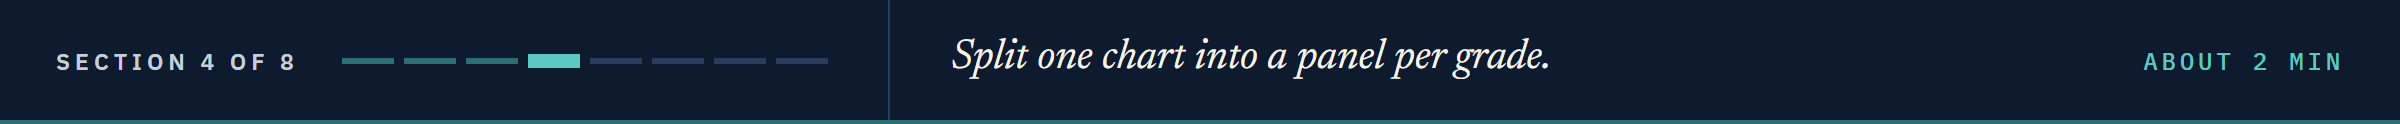

## 12.4 Catplot

`catplot()` draws any of these by `kind=`, with a panel per value of `col=`; like `displot()`, it returns a grid.

### A Panel per Grade

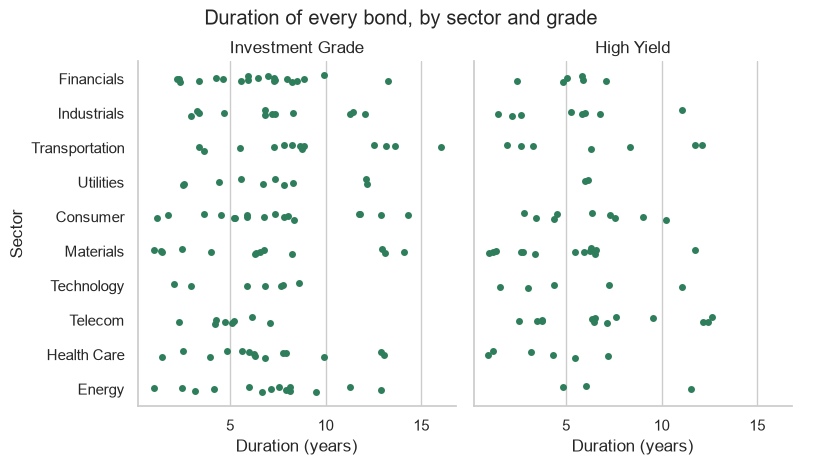

In [13]:
np.random.seed(0)
# kind='strip' picks the chart, col='grade' a panel per grade; the sectors run down the side
# kind='swarm', 'violin', 'bar' or 'point' would redraw the same split
grid = sns.catplot(data=book, x='duration', y='sector', col='grade', kind='strip',
                   height=4.5, aspect=0.9)
grid.set_axis_labels('Duration (years)', 'Sector')
grid.set_titles('{col_name}')
grid.figure.suptitle('Duration of every bond, by sector and grade', y=1.03)
plt.show()

Read a row across: Utilities has 10 Investment Grade dots and 2 High Yield.
The dot furthest right, in Transportation, is the 16.04-year bond.

### Averages and Their Range

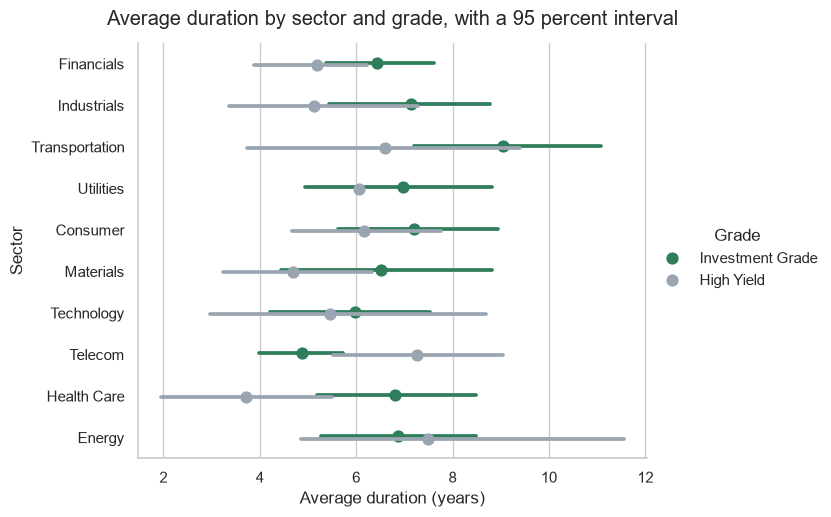

In [14]:
# kind='point': each group's average as a dot, with Visualization's 95 percent interval
# hue= colours by grade, dodge=True sets the two grades apart, linestyle='none' joins no dots
grid = sns.catplot(data=book, x='duration', y='sector', hue='grade', kind='point',
                   errorbar=('ci', 95), seed=0, dodge=True, linestyle='none', height=5, aspect=1.4)
grid.set_axis_labels('Average duration (years)', 'Sector')
grid.legend.set_title('Grade')
grid.figure.suptitle('Average duration by sector and grade, with a 95 percent interval', y=1.03)
plt.show()

Energy High Yield, 3 bonds far apart, has the longest line; Utilities High Yield, 2 bonds near 6 years, almost none, though 2 bonds make no sure average.

**Excel side by side.** A panel per group is one chart per group, each from the filtered table; `=COUNTIFS(E:E, "Utilities", V:V, "High Yield")` gives the 2.

**Averages say where the middle is; the dots say how many stand behind it. Back to one scatter, and how crowded it is.**

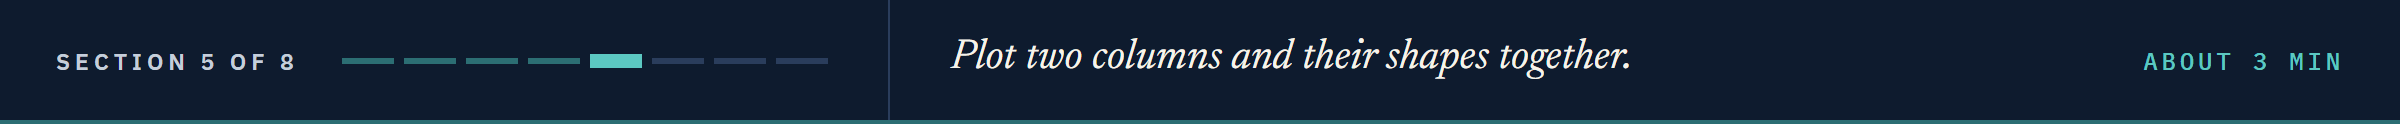

## 12.5 Joint Plot

A **joint plot** puts a scatter in the middle and each column's histogram along its side.

### The Scatter and Each Column's Shape

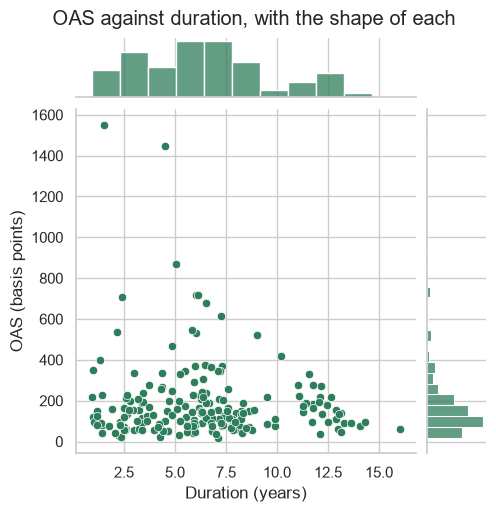

In [15]:
# jointplot(): its own square figure; height= its size in inches
grid = sns.jointplot(data=book, x='duration', y='oas', height=5)
grid.set_axis_labels('Duration (years)', 'OAS (basis points)')
grid.figure.suptitle('OAS against duration, with the shape of each', y=1.02)
plt.show()

Along the top is duration's histogram; down the right, Visualization's OAS histogram on its side, 164 below 250 bp.
The dots crowd the bottom because the OAS column does, at every duration.

### A Crowd in Hexagons

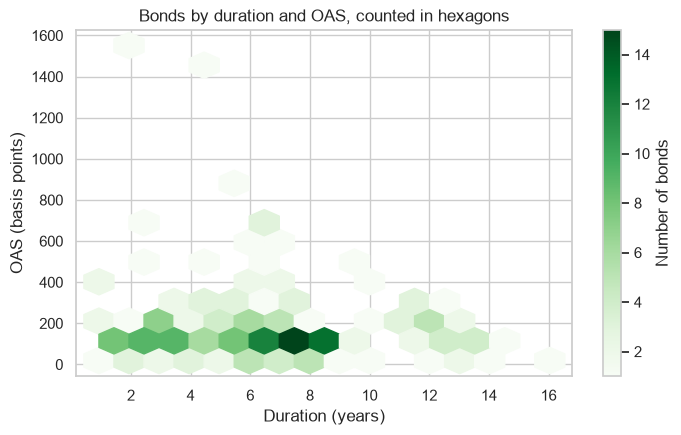

Most bonds in one hexagon: 15


In [16]:
# hexbin(): hexagons shaded by the bonds inside; gridsize= hexagons across,
# mincnt=1 leaves empty ones blank
fig, ax = plt.subplots(figsize=(8, 4.5))
hexes = ax.hexbin(book['duration'], book['oas'], gridsize=15, cmap='Greens', mincnt=1)
# colorbar(): the key from shade to count;
# jointplot(kind='hex') draws hexagons with side histograms
fig.colorbar(hexes, ax=ax, label='Number of bonds')
ax.set_title('Bonds by duration and OAS, counted in hexagons')
ax.set_xlabel('Duration (years)')
ax.set_ylabel('OAS (basis points)')
plt.show()
# get_array(): the count in every hexagon
print('Most bonds in one hexagon:', int(hexes.get_array().max()))

The darkest hexagon sits low, near 7 to 8 years; the widest bonds are pale singles far above.

### Smoothed, Then Split by Grade

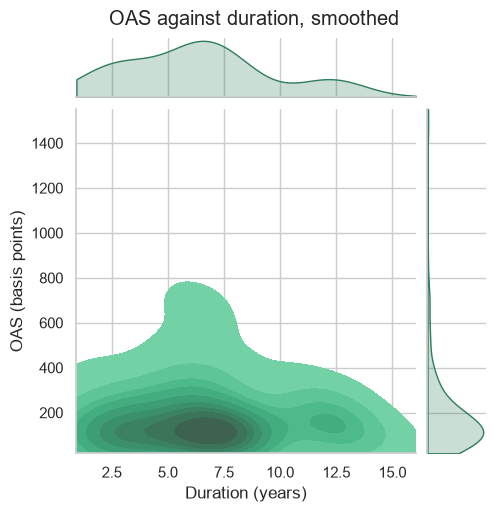

In [17]:
# kind='kde': contours of equal density, fill=True shades them
# cut=0 stops them at the data, and marginal_kws= hands the same to the side curves
grid = sns.jointplot(data=book, x='duration', y='oas', kind='kde', fill=True, cut=0,
                     marginal_kws={'cut': 0}, height=5)
grid.set_axis_labels('Duration (years)', 'OAS (basis points)')
grid.figure.suptitle('OAS against duration, smoothed', y=1.02)
plt.show()

The fill shows one dense area near 6 to 7 years and a smaller one near 12; the widest bonds vanish, since a density averages over them.

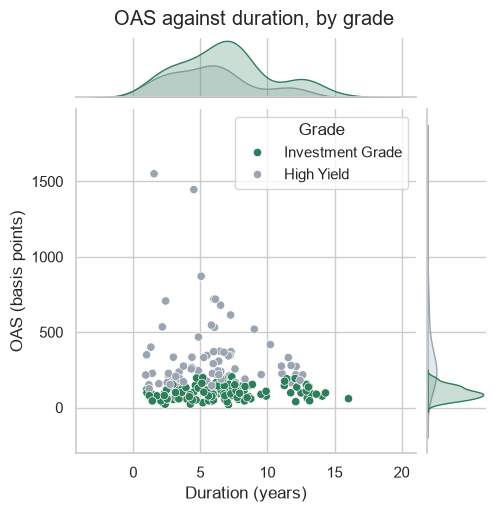

In [18]:
# hue= colours by grade, and the sides become a smooth curve per grade;
# ax_joint is the middle panel
# kind='reg' in place of hue= would add the fitted line
grid = sns.jointplot(data=book, x='duration', y='oas', hue='grade', height=5)
grid.set_axis_labels('Duration (years)', 'OAS (basis points)')
grid.ax_joint.legend(title='Grade')
grid.figure.suptitle('OAS against duration, by grade', y=1.02)
plt.show()

On the right, Investment Grade is a tall narrow peak and High Yield low and long; along the top the grades overlap.
Both side curves run below zero, as Predict 2 warned.

**Excel side by side.** No single chart: a Scatter with two Histograms beside it, and `=COUNTIF(M:M, "<250")` for the 164.

**A crowd hides which bond is which. Next, a chart that names it when you point.**

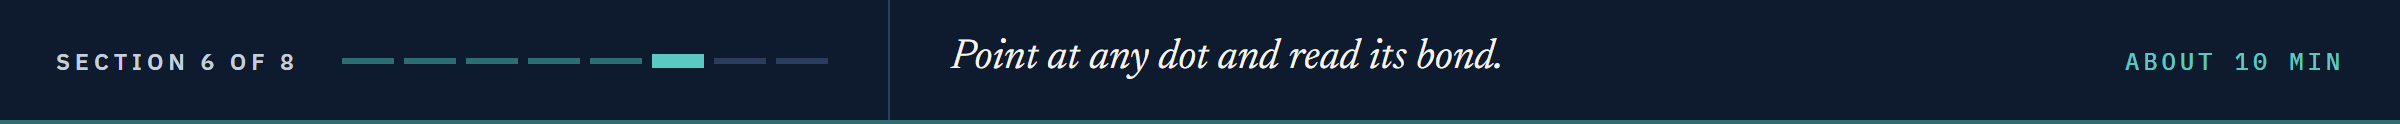

## 12.6 Interactive Charts With plotly

An **interactive chart** answers the mouse: rest on a dot for its values, drag to zoom, double-click to reset, click a legend name to hide it.
GitHub shows none of these, so a still picture sits under each.

### Point at a Bond

Q. Draw OAS against duration so that pointing at a dot names the bond.

In [19]:
# px is plotly.express: one call from a table, as with seaborn; white, in the house greens
import plotly.express as px
px.defaults.template = 'plotly_white'
px.defaults.color_discrete_sequence = ['#2E7D5B', '#9AA5B1']
# color= is plotly's hue=; hover_name= heads the box at a dot, hover_data= adds columns,
# labels= renames
fig = px.scatter(book, x='duration', y='oas', color='grade', hover_name='issuer',
                 hover_data=['ticker', 'rating'], title='OAS against duration, one dot per bond',
                 labels={'duration': 'Duration (years)', 'oas': 'OAS (basis points)',
                         'grade': 'Grade'})
# add_annotation(): a note at a point, in the axes' units; widest is the row with the largest OAS
# there is no ax: title and labels are arguments, and fig.show() draws the figure
widest = book.loc[book['oas'].idxmax()]
fig.add_annotation(x=widest['duration'], y=widest['oas'], text=widest['ticker'])
fig.show()

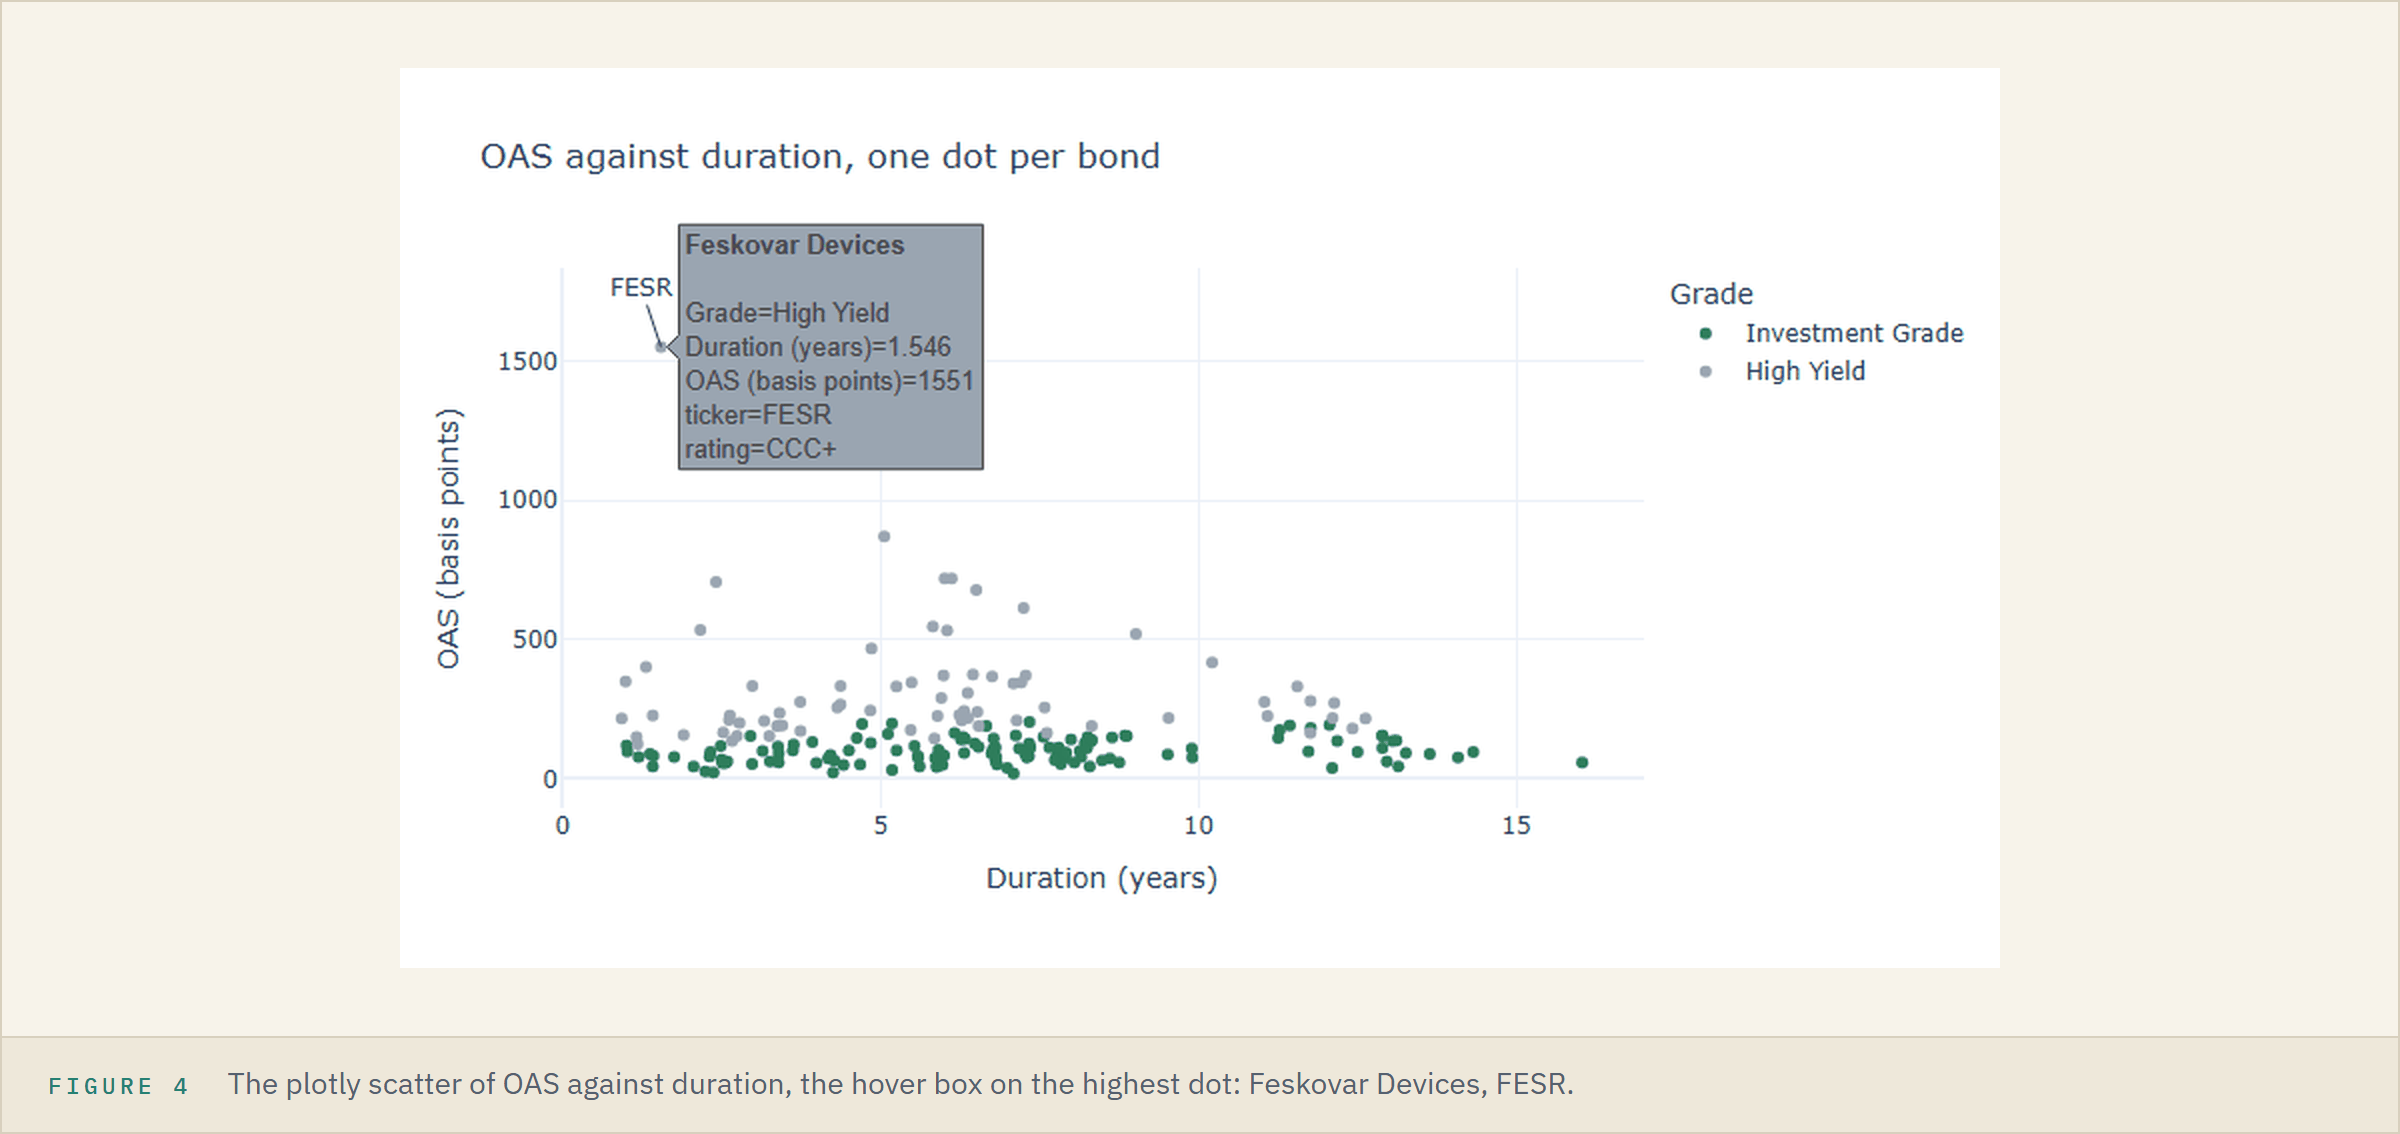

The top dot is Feskovar Devices, an invented issuer: FESR, rated CCC+, at 1.546 years and 1,551 bp.

### A Box With Every Bond

In [20]:
# px.box(): a box per grade; points='all' draws every bond beside it
fig = px.box(book, x='grade', y='oas', points='all', hover_name='issuer',
             labels={'grade': 'Grade', 'oas': 'OAS (basis points)'},
             title='OAS by grade, every bond shown')
fig.show()

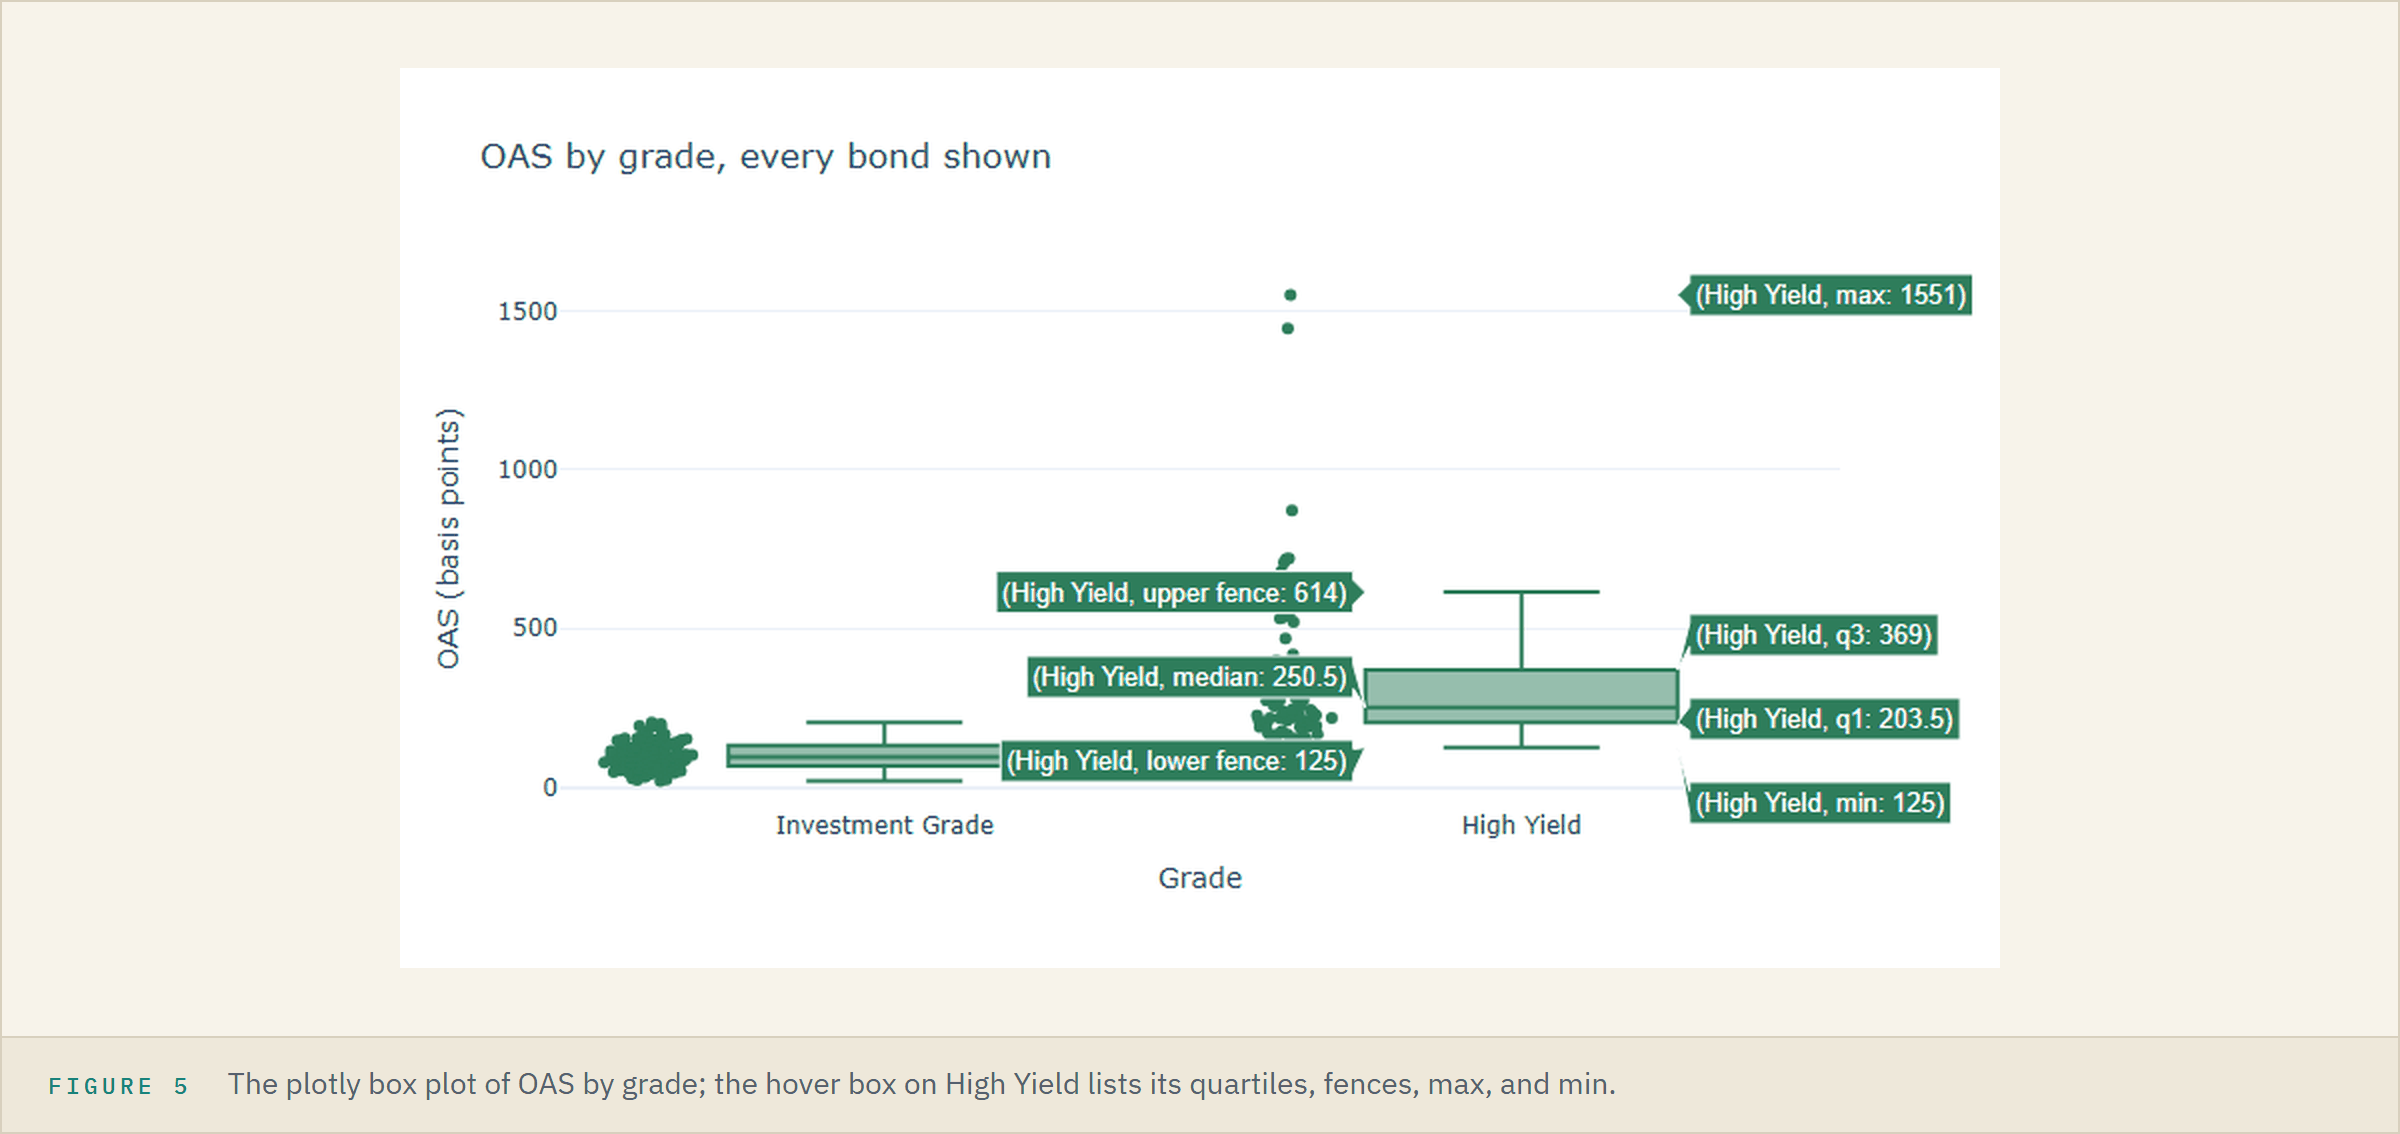

Point at a box for its quartiles, or at a dot for its bond: Visualization's circles now have names.

### Market Value, Stacked by Grade

In [21]:
# a group per sector and grade, as in the Joining the Tables case study's by_two;
# reset_index() turns the two labels back into columns, the table px wants
value_table = (book.groupby(['sector', 'grade'])['market_value'].sum()
               / 1_000_000).round(2).reset_index()
# the sectors from the largest total to the smallest
sector_totals = value_table.groupby('sector')['market_value'].sum()
sector_order = sector_totals.sort_values(ascending=False).index.tolist()
# px.bar() stacks rows that share a sector; category_orders= fixes the order of sectors and grades
fig = px.bar(value_table, x='sector', y='market_value', color='grade',
             category_orders={'sector': sector_order, 'grade': ['Investment Grade', 'High Yield']},
             labels={'sector': 'Sector', 'market_value': 'Market value (millions of dollars)',
                     'grade': 'Grade'},
             title='Market value by sector and grade')
fig.show()

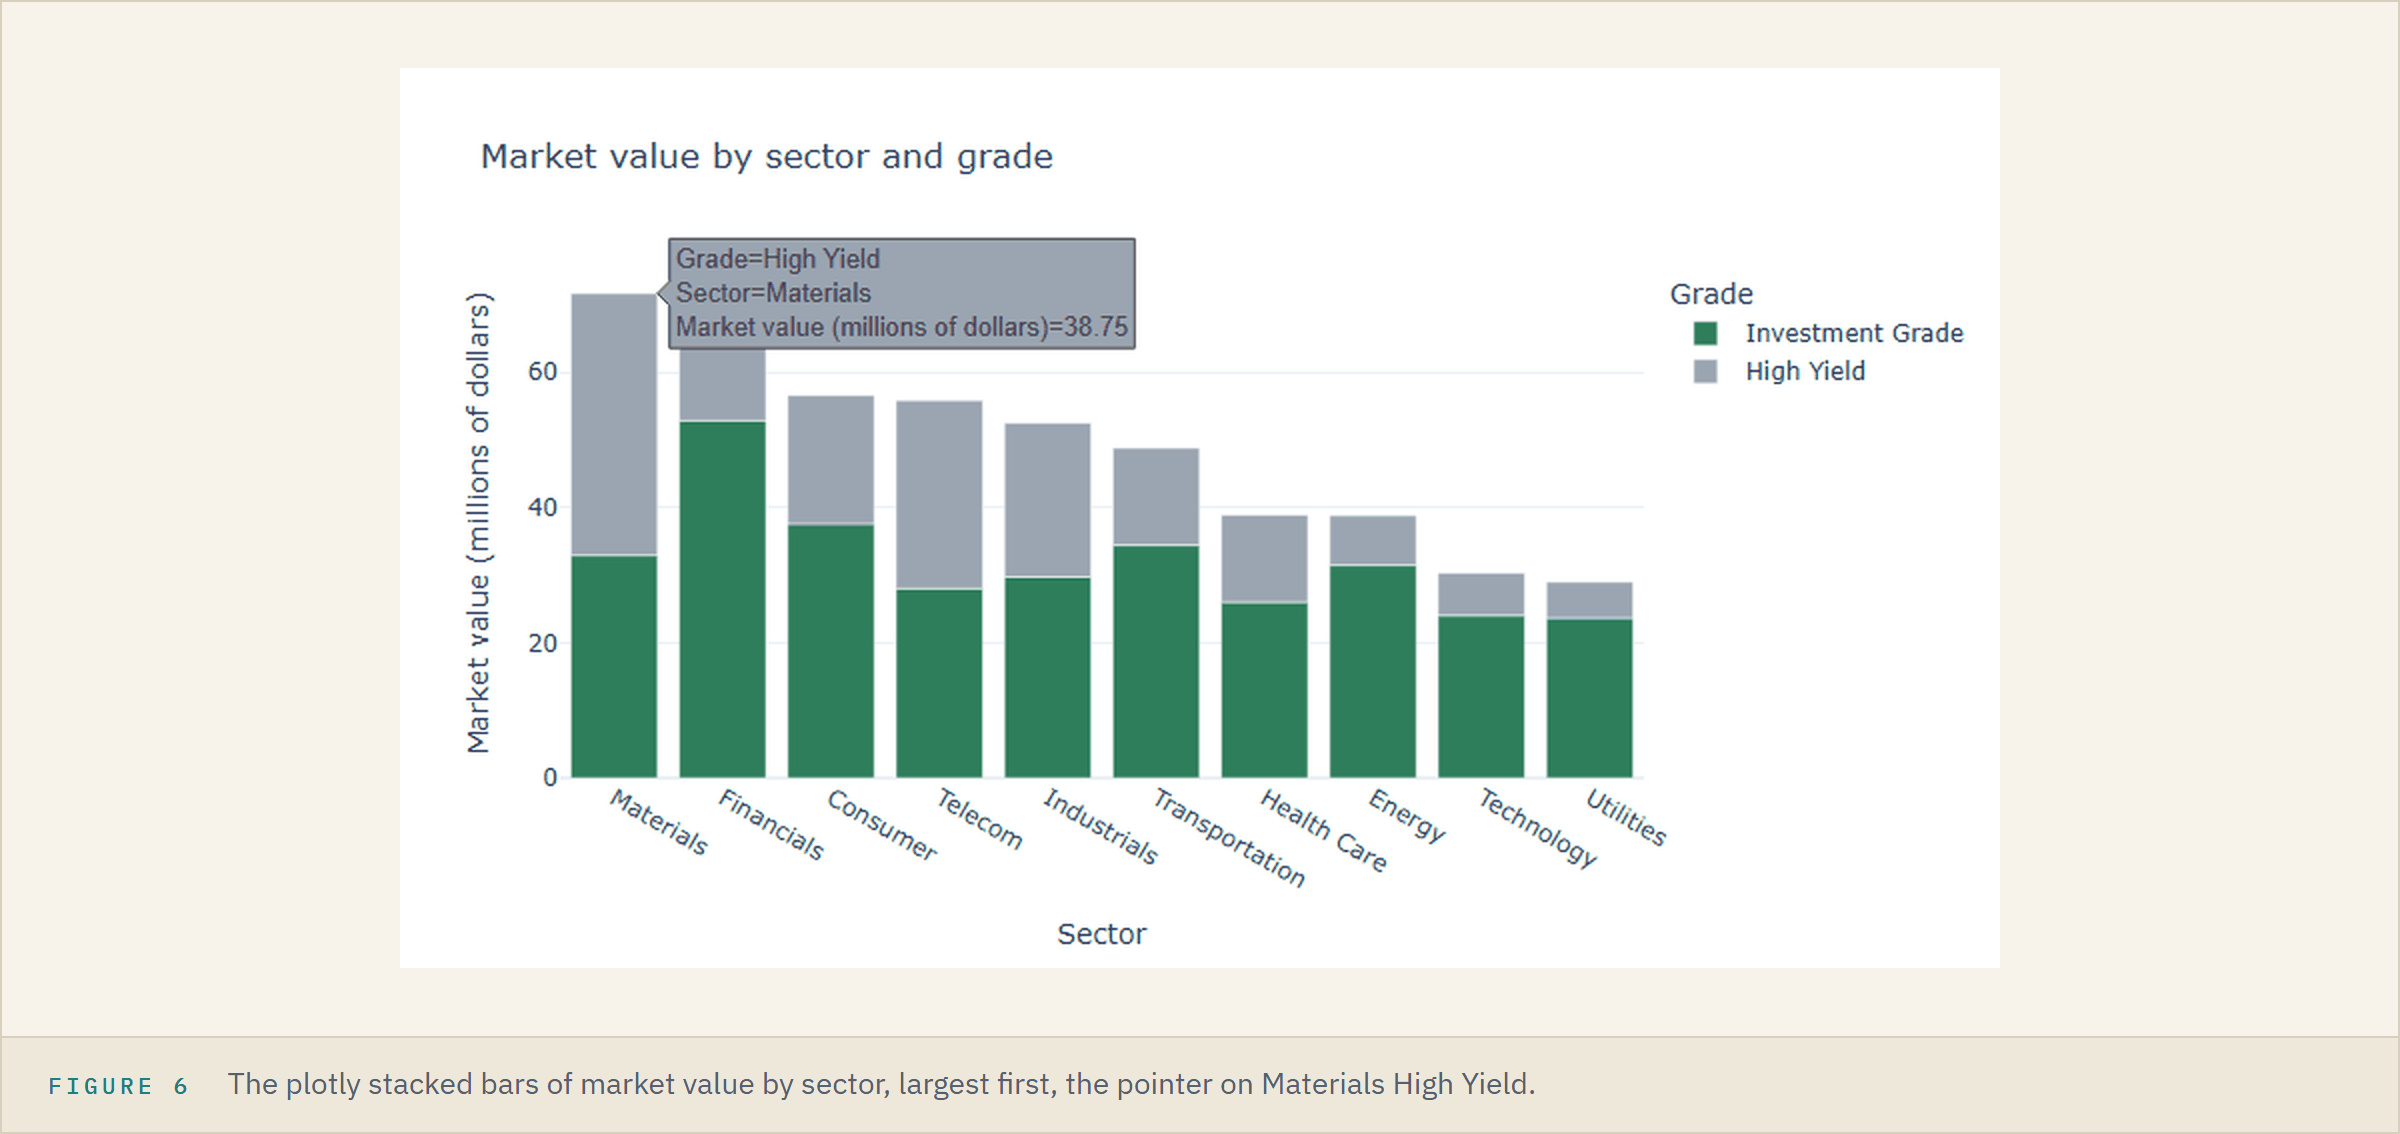

Materials leads with 71.70 million, then Financials with 68.22, as in Visualization; point at a piece for its value.
Click Investment Grade in the legend and the bars redraw from zero, High Yield alone.

### Save It as a Web Page

In [22]:
# write_html(): the chart as a web page; include_plotlyjs='cdn' has the browser fetch plotly's code
fig.write_html('market_value_by_sector.html', include_plotlyjs='cdn')
# os.path.getsize(): a file's size in bytes
print('Saved:', os.path.exists('market_value_by_sector.html'),
      os.path.getsize('market_value_by_sector.html'), 'bytes')
# remove it, so the folder is as it was found
os.remove('market_value_by_sector.html')

Saved: True 9304 bytes


Anyone can open the file and point, with no Python; without `'cdn'` it carries all of plotly, megabytes.
It also carries every number behind the chart, so treat it as the spreadsheet it came from.

### A Third Dimension

In [23]:
# DTS is spread duration times OAS: check that, then draw all three
print('Duration equals spread duration:',
      (book['duration'] == book['spread_duration']).sum(), 'of 200')
gap = book['dts'] - book['spread_duration'] * book['oas']
print('Gap from DTS:', round(gap.min(), 2), 'to', round(gap.max(), 2))
# scatter_3d(): px.scatter() with z=; update_traces() shrinks the dots after the figure is made
fig = px.scatter_3d(book, x='duration', y='oas', z='dts', color='grade', hover_name='issuer',
                    labels={'duration': 'Duration (years)', 'oas': 'OAS (bp)', 'dts': 'DTS',
                            'grade': 'Grade'},
                    title='Duration, OAS, and DTS of the 200 bonds')
fig.update_traces(marker={'size': 3})
fig.show()

Duration equals spread duration: 200 of 200
Gap from DTS: -0.05 to 0.05


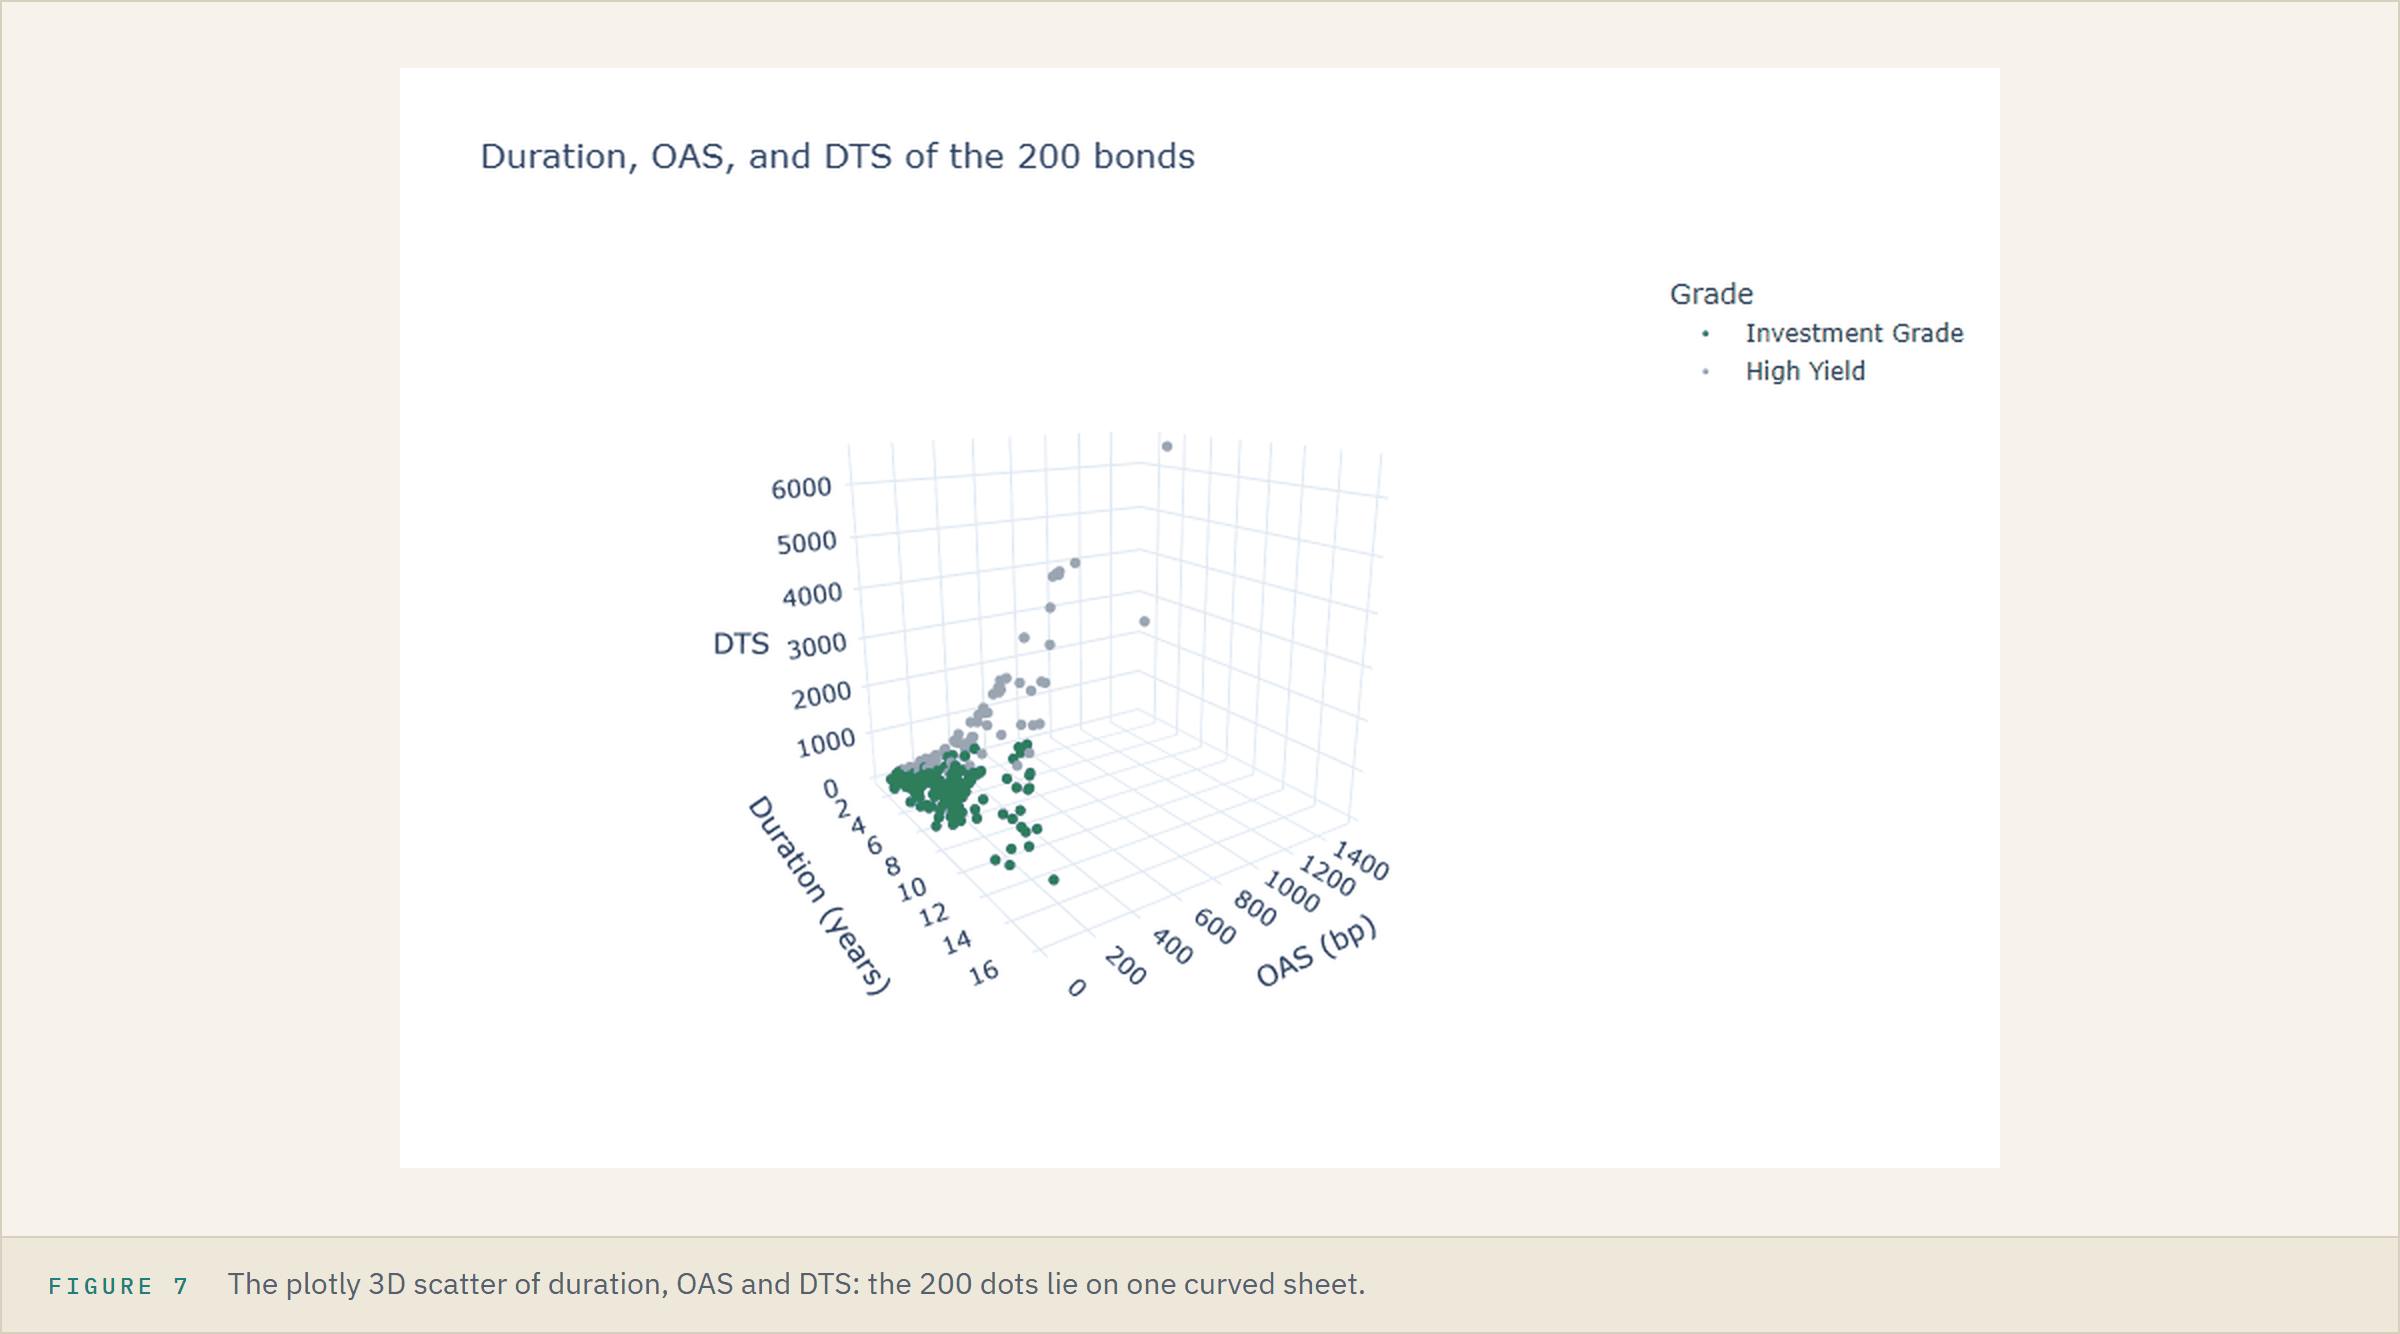

Drag to turn it: from the right angle the dots lie on one curved sheet, `z = x * y`, as the check said.
On paper, where depth is lost, use flat panels or a heatmap.

### A Surface From a Formula

A **surface** draws a formula, a height for every pair of x and y: here NumPy Part 2's discounted cash flows, summed in one line.

In [24]:
def bond_price(yield_pct, years, coupon=5.0):
    # y: the yield per half-year as a decimal; n: the half-years left
    y = yield_pct / 100 / 2
    n = years * 2
    return coupon / 2 * (1 - (1 + y) ** -n) / y + 100 * (1 + y) ** -n


print(round(bond_price(5, 10), 2), round(bond_price(5, 30), 2),
      round(bond_price(10, 30), 2), round(bond_price(1, 30), 2))

100.0 100.0 52.68 203.45


At a yield equal to the coupon the price is 100; at 30 years it is 52.68 at 10 percent and 203.45 at 1 percent, arithmetic on an imagined bond.

In [25]:
# meshgrid(): every pair of 2 yields and 3 maturities, as two tables of one shape
small_yields, small_years = np.meshgrid([4, 6], [1, 2, 3])
print(small_yields)
print(small_years)

[[4 6]
 [4 6]
 [4 6]]
[[1 1]
 [2 2]
 [3 3]]


Bottom right in both: a yield of 6 at 3 years, one of six pairs.

In [26]:
# 19 yields and 30 maturities, every pair priced in one call
yields = np.arange(1, 10.5, 0.5)
years = np.arange(1, 31)
yield_grid, years_grid = np.meshgrid(yields, years)
price_grid = bond_price(yield_grid, years_grid)
print(price_grid.shape, '1 year:',
      round(price_grid[0].min(), 2), 'to', round(price_grid[0].max(), 2))

(30, 19) 1 year: 95.35 to 103.97


In [27]:
# go is plotly's layer under px: go.Figure() holds a chart, go.Surface() takes the two axes,
# the table of heights, and colorscale=, its colours from low to high
import plotly.graph_objects as go
fig = go.Figure(go.Surface(x=yields, y=years, z=price_grid, colorscale='Greens'))
# update_layout(): settings after the figure is made; scene= titles the three axes
fig.update_layout(title='Price of a 5 percent bond, by yield and maturity', scene={
    'xaxis_title': 'Yield (percent)', 'yaxis_title': 'Maturity (years)',
    'zaxis_title': 'Price (per 100)'})
fig.show()

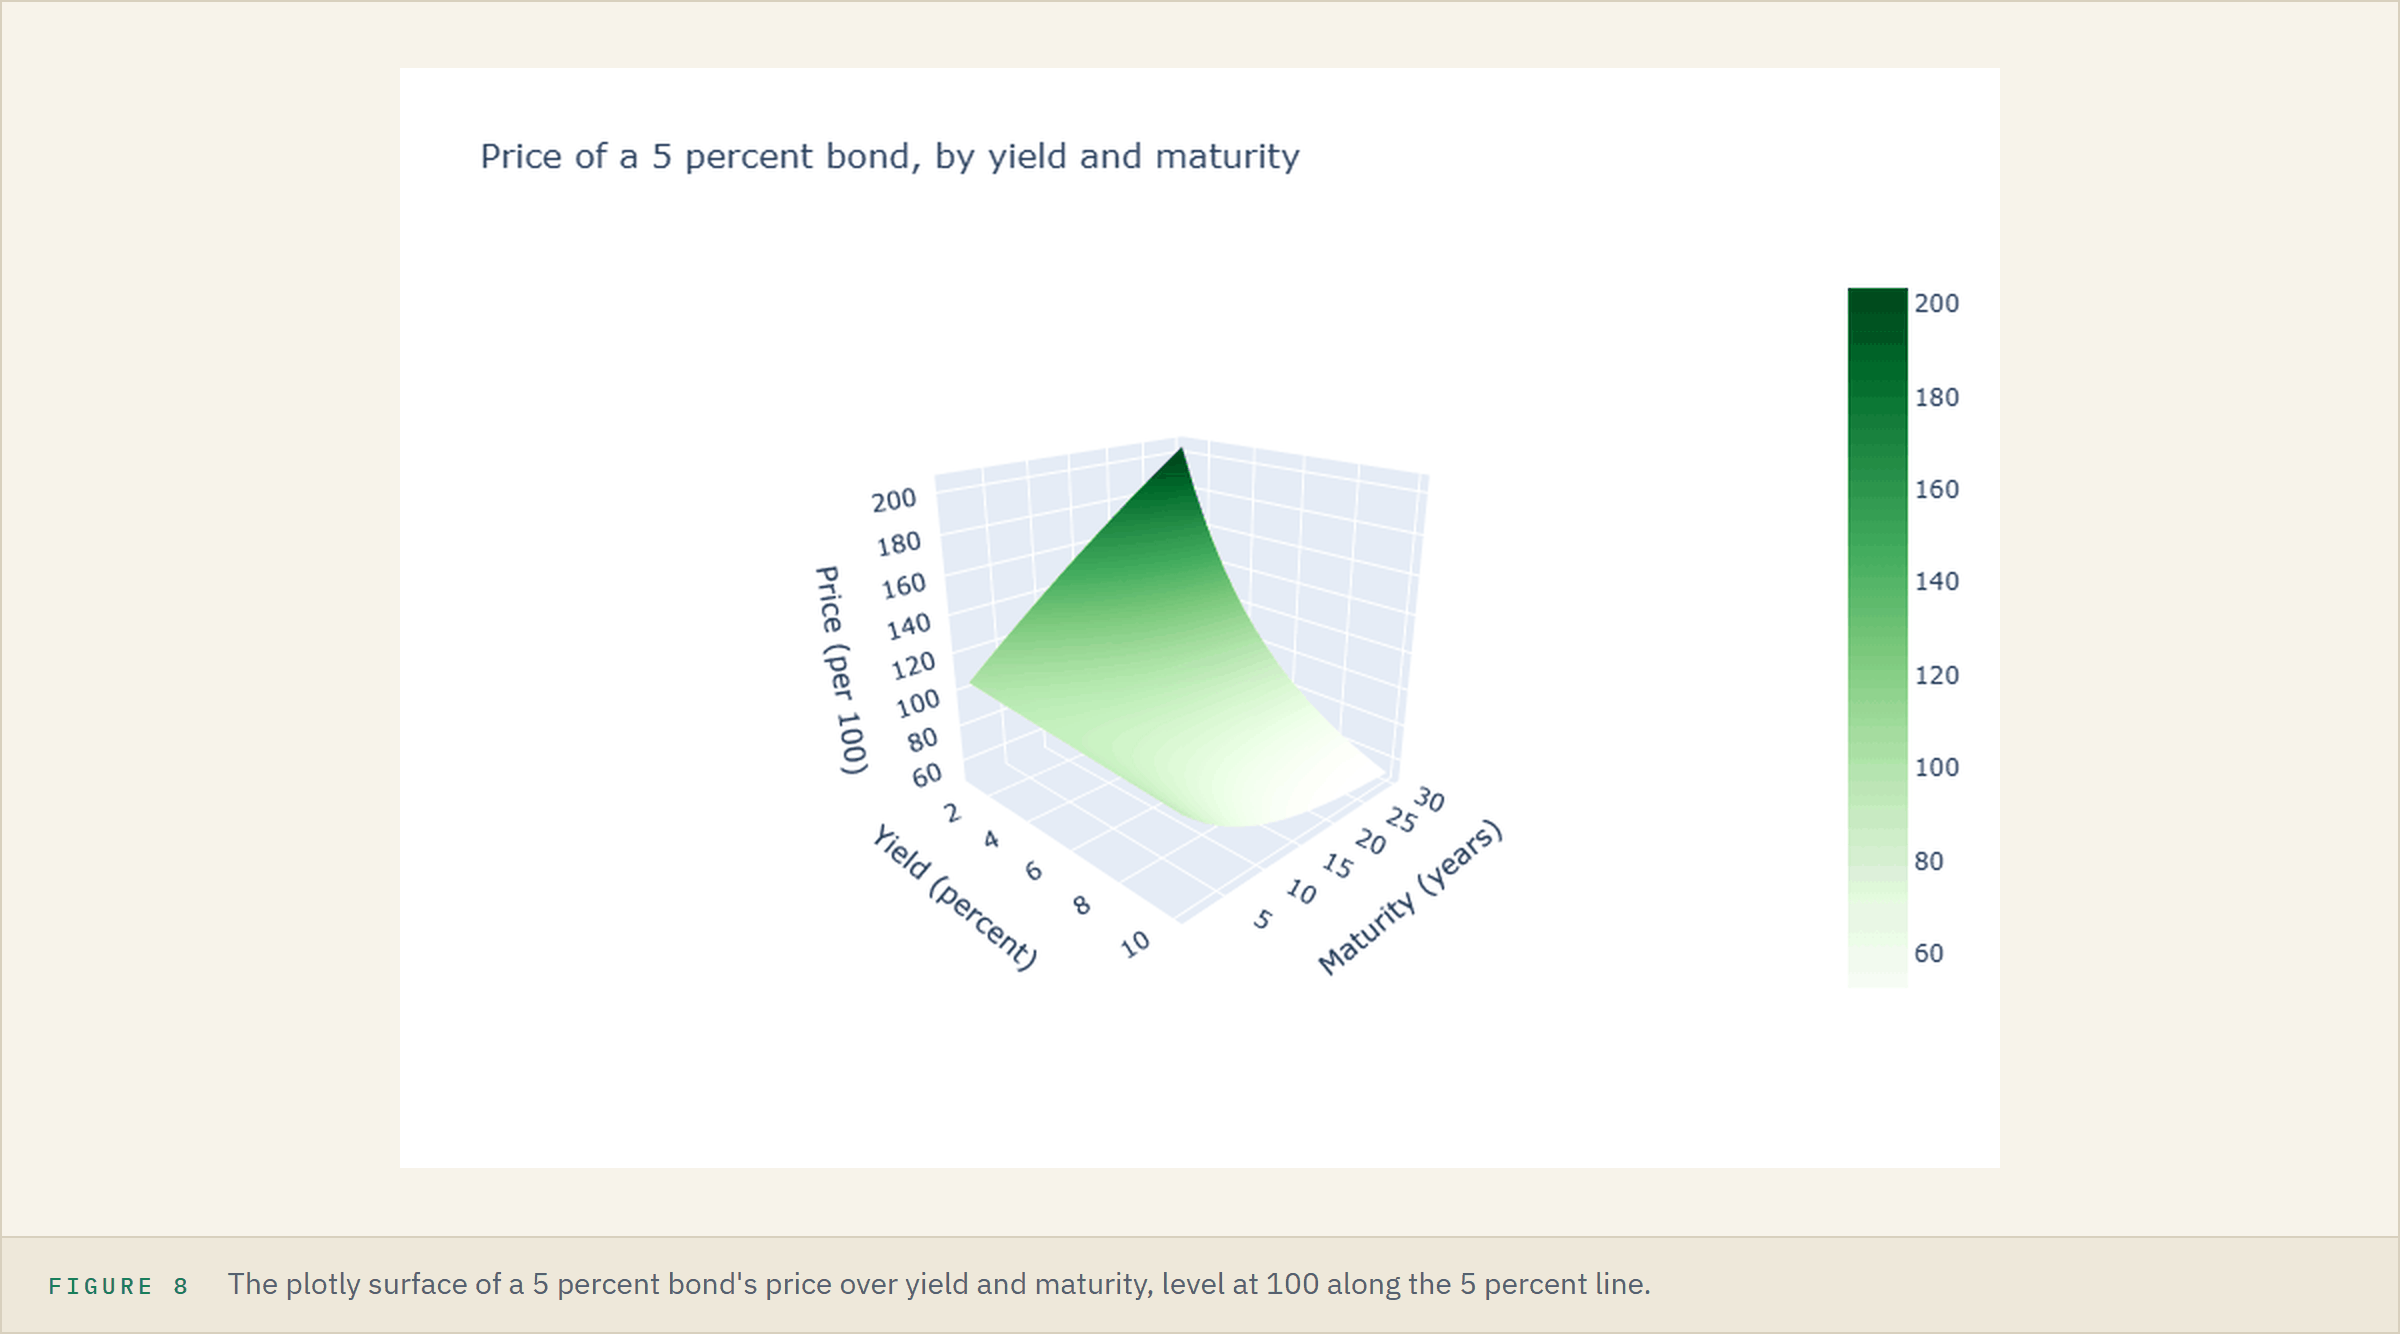

The prices lie nearly flat along the 1-year edge, 95.35 to 103.97, fan out at 30 years, and stay at 100 along the 5 percent line.

**Excel side by side.** Market value is column S, sector E, grade V.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Read a point</td><td align="left">the hover box</td><td align="left">rest the pointer: a tip with the series and value</td></tr>
<tr><td align="left">One stacked piece</td><td align="left">Consumer, High Yield, 19.02</td><td align="left"><code>=SUMIFS(S:S, E:E, "Consumer", V:V, "High Yield") / 1000000</code></td></tr>
<tr><td align="left">A bond's price</td><td align="left"><code>bond_price(10, 30)</code>, 52.68</td><td align="left"><code>=PRICE(DATE(2026,9,15), DATE(2056,9,15), 0.05, 0.1, 100, 2)</code></td></tr>
</table>
<br clear="left">

**On screen a chart can answer the mouse; a meeting still wants a still picture in the desk's look.**

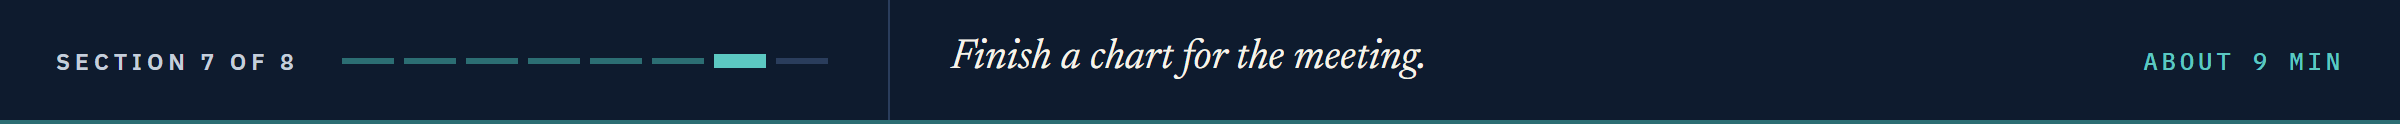

## 12.7 Customizing a Chart

### The Desk's Colours

Q. Give each grade one colour for every chart in the pack.

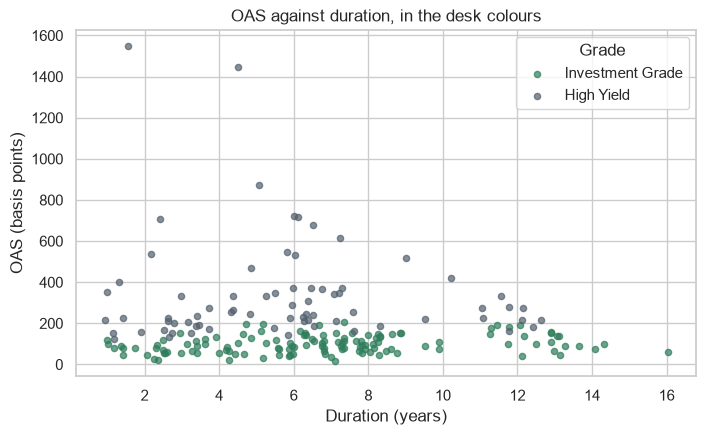

In [28]:
# a dict of hex codes, written once: '#' then the red, green and blue, two digits each
grade_colours = {'Investment Grade': '#2E7D5B', 'High Yield': '#52606D'}
fig, ax = plt.subplots(figsize=(8, 4.5))
# items() gives each grade with its colour: one scatter() per grade
for grade, colour in grade_colours.items():
    part = book[book['grade'] == grade]
    ax.scatter(part['duration'], part['oas'], color=colour, s=20, alpha=0.7, label=grade)
ax.legend(title='Grade')
ax.set_title('OAS against duration, in the desk colours')
ax.set_xlabel('Duration (years)')
ax.set_ylabel('OAS (basis points)')
plt.show()

The two widest bonds stretch the axis to 1,551 and press the crowd flat.

### Predict 3: A Narrower Axis

**Predict 3**

Q. 8 bonds have an OAS above 600 bp. What happens to them after `ax.set_ylim(0, 600)`?

A) They are deleted from `book`.
B) They stay in `book`, are not drawn, and nothing on the chart says so.
C) An error: data falls outside the axis.

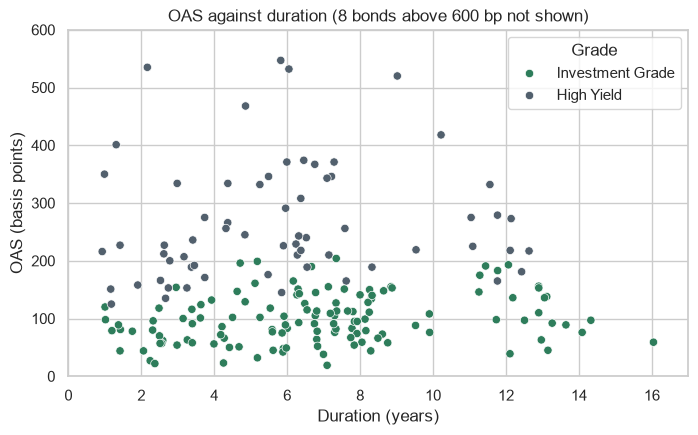

Rows in book: 200   OAS above 600 bp: 8


In [29]:
fig, ax = plt.subplots(figsize=(8, 4.5))
# palette= takes the dict too, so seaborn draws each grade in its desk colour
sns.scatterplot(data=book, x='duration', y='oas', hue='grade', palette=grade_colours, ax=ax)
# set_ylim(): the bottom and top of the y axis; set_xlim() the same across
ax.set_ylim(0, 600)
ax.set_xlim(0, 17)
# loc= puts the legend in the corner you name
ax.legend(title='Grade', loc='upper right')
ax.set_title('OAS against duration (8 bonds above 600 bp not shown)')
ax.set_xlabel('Duration (years)')
ax.set_ylabel('OAS (basis points)')
plt.show()
print('Rows in book:', len(book), '  OAS above 600 bp:', (book['oas'] > 600).sum())

B: they stay in `book`; the axis is a window, and 8 bonds are outside it.
matplotlib gives no sign, so the title must, or the chart misleads.

### Every Bond on a Log Scale

Q. Keep all 200 and point at the widest bond.

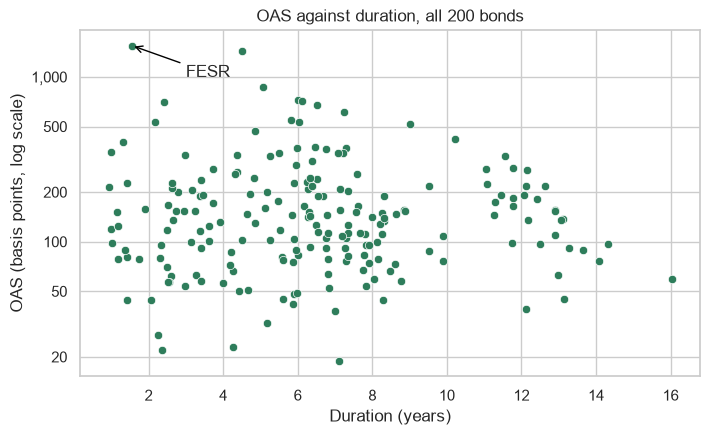

In [30]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=book, x='duration', y='oas', ax=ax)
# a log scale, as in Visualization; set_yticks() names the ticks to show and their labels
ax.set_yscale('log')
ax.set_yticks([20, 50, 100, 200, 500, 1000], ['20', '50', '100', '200', '500', '1,000'])
# Visualization's arrow, pointing at the widest row
ax.annotate(widest['ticker'], xy=(widest['duration'], widest['oas']), xytext=(3, 1000),
            arrowprops={'arrowstyle': '->', 'color': 'black'})
ax.set_title('OAS against duration, all 200 bonds')
ax.set_xlabel('Duration (years)')
ax.set_ylabel('OAS (basis points, log scale)')
plt.show()

All 200 are on, and 50 to 100 stands as tall as 500 to 1,000: each is a doubling.
OAS runs from 19 to 1,551 bp, the kind of range a log axis is for.

**Cut points off and say so, or keep them all on a log axis and say so.**

### Dollars a Reader Can Read

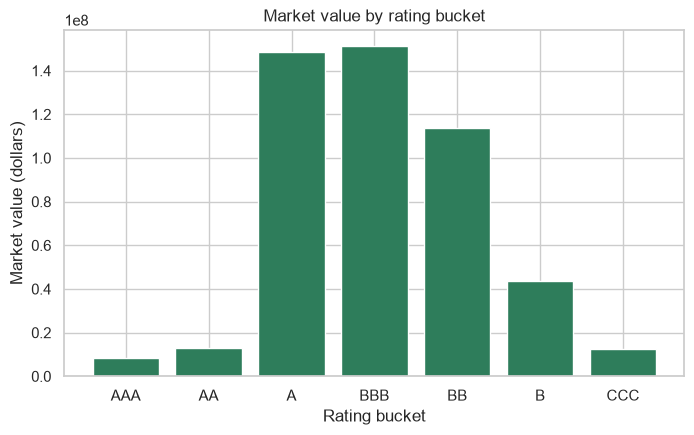

In [31]:
# each bucket's market value in dollars, in credit order, and its share of the book in percent
value_by_bucket = book.groupby('bucket')['market_value'].sum().loc[bucket_order]
share_by_bucket = value_by_bucket / value_by_bucket.sum() * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(value_by_bucket.index, value_by_bucket.values)
ax.set_title('Market value by rating bucket')
ax.set_xlabel('Rating bucket')
ax.set_ylabel('Market value (dollars)')
plt.show()

The ticks read 0.0 to 1.4 under a small `1e8`: matplotlib divided by 100,000,000 and left a note, correct and easy to misread.

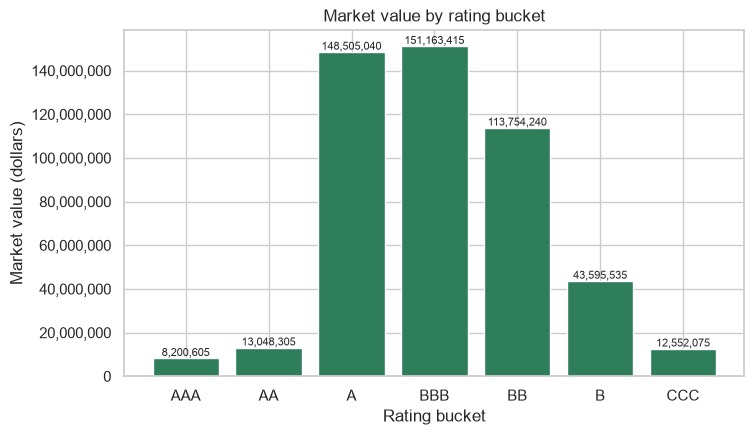

In [32]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(value_by_bucket.index, value_by_bucket.values)
# bar_label() with braces: a comma for thousands and no decimals;
# fontsize= smaller, so long numbers fit
ax.bar_label(bars, fmt='{:,.0f}', fontsize=8)
# ax.yaxis is the y axis; set_major_formatter() writes its ticks, with x for each number
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.set_title('Market value by rating bucket')
ax.set_xlabel('Rating bucket')
ax.set_ylabel('Market value (dollars)')
plt.show()

### Shares in Percent

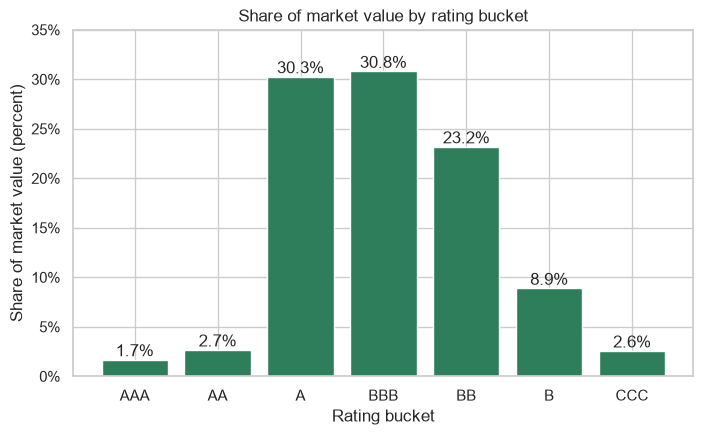

In [33]:
# PercentFormatter writes ticks as percents: xmax=100 says the values already are,
# decimals=0 whole ones
from matplotlib.ticker import PercentFormatter
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(share_by_bucket.index, share_by_bucket.values)
# '%.1f%%': one decimal, then %% for a percent sign
ax.bar_label(bars, fmt='%.1f%%')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
# headroom for the labels; the bottom stays at zero
ax.set_ylim(0, 35)
ax.set_title('Share of market value by rating bucket')
ax.set_xlabel('Rating bucket')
ax.set_ylabel('Share of market value (percent)')
plt.show()

### Predict 4: Bars From 147

**Predict 4**

Q. A holds 148.51 million and BBB 151.16 million. With the value axis starting at 147 million, how many times as tall as A's bar is BBB's? Write down a number.

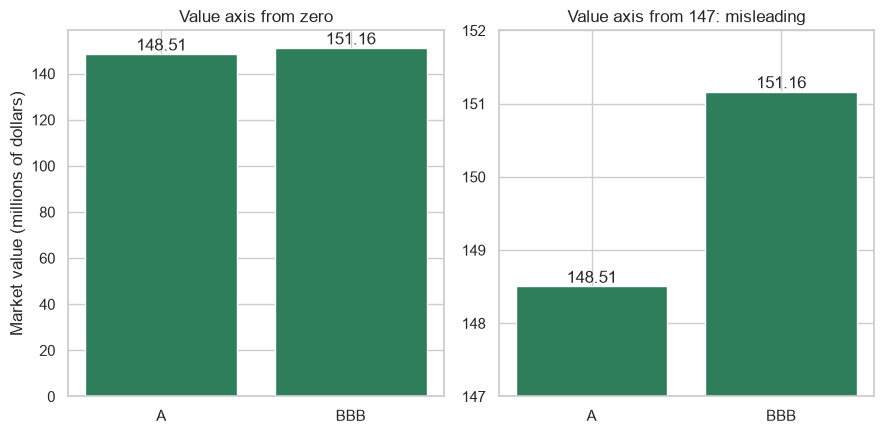

In [34]:
# the two buckets in millions; subplots(1, 2): one row of two axes, axes[0] on the left
two = value_by_bucket[['A', 'BBB']] / 1_000_000
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
# zip() pairs each panel with its title
for ax, title in zip(axes, ['Value axis from zero', 'Value axis from 147: misleading']):
    bars = ax.bar(two.index, two.values)
    ax.bar_label(bars, fmt='%.2f')
    ax.set_title(title)
axes[1].set_ylim(147, 152)
axes[0].set_ylabel('Market value (millions of dollars)')
# tight_layout() spaces the panels so their labels do not collide
plt.tight_layout()
plt.show()

In [35]:
# BBB against A: their values, then their bar lengths measured from 147
print('Values:', round(two['BBB'] / two['A'], 2),
      '  lengths from 147:', round((two['BBB'] - 147) / (two['A'] - 147), 2))

Values: 1.02   lengths from 147: 2.77


BBB's bar stands 2.77 times as tall as A's for a gap of 2 percent: the left panel's near-equal bars are the truth.
matplotlib starts a bar's axis at zero unless told; Excel picks its minimum from the data, 147 here and 0 for all seven bars, so set Format Axis, Bounds, Minimum to 0.
`ax.twinx()` adds a second unit on a right-hand axis, where lines cross wherever the scales put them: give each unit its own panel.

**A bar is read by its length: its axis starts at zero.**

### Colours Everyone Can Tell Apart

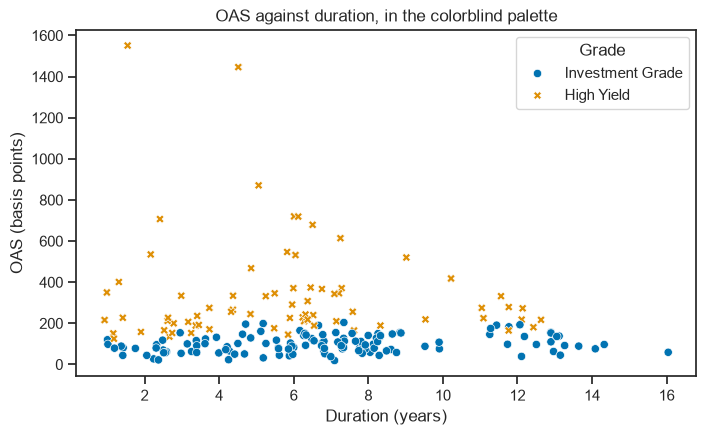

In [36]:
# with: a style that holds only inside the block, as week 1's Day 2 with open() held a file
with sns.axes_style('ticks'):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    # palette='colorblind': seaborn's colours chosen for colour-blind readers;
    # style= a shape per grade
    sns.scatterplot(data=book, x='duration', y='oas', hue='grade', style='grade',
                    palette='colorblind', ax=ax)
    ax.legend(title='Grade')
    ax.set_title('OAS against duration, in the colorblind palette')
    ax.set_xlabel('Duration (years)')
    ax.set_ylabel('OAS (basis points)')
    plt.show()
# ax.set_axis_off() would hide the axes entirely, for a picture with no scale to read

The `ticks` look, with no grid, lasts for this chart alone.

### Two Panels, One Scale

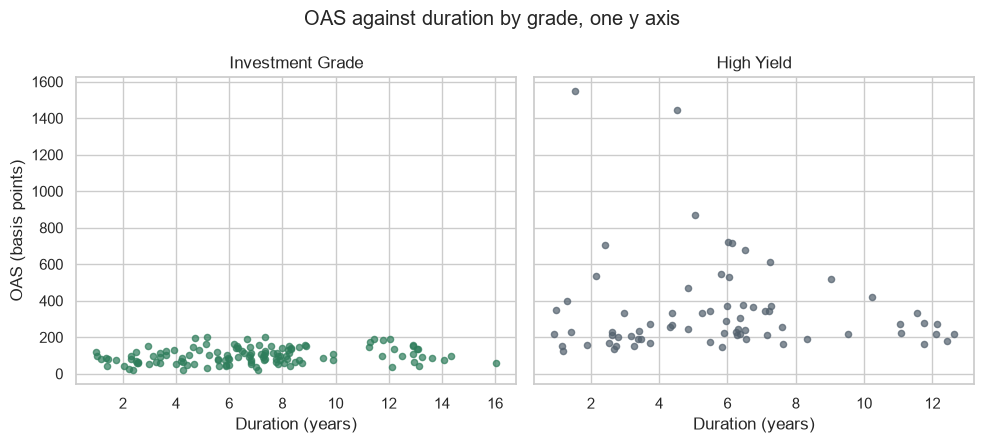

In [37]:
# sharey=True: both panels on one y axis, so heights compare
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, grade in zip(axes, grade_colours):
    part = book[book['grade'] == grade]
    ax.scatter(part['duration'], part['oas'], color=grade_colours[grade], s=20, alpha=0.7)
    ax.set_title(grade)
    ax.set_xlabel('Duration (years)')
axes[0].set_ylabel('OAS (basis points)')
fig.suptitle('OAS against duration by grade, one y axis')
plt.tight_layout()
plt.show()

On one scale Investment Grade is a flat band under 204 bp; without `sharey=True` both panels would look equally tall.

### One Desk Style, Saved for the Slide

In [38]:
def desk_style(ax, title, xlabel, ylabel):
    # a bold title on the left, and the two labels with their units
    ax.set_title(title, loc='left', fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    # spines are the plot's four edges: drop the top and right
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # grid lines across only, kept behind the bars
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(True)

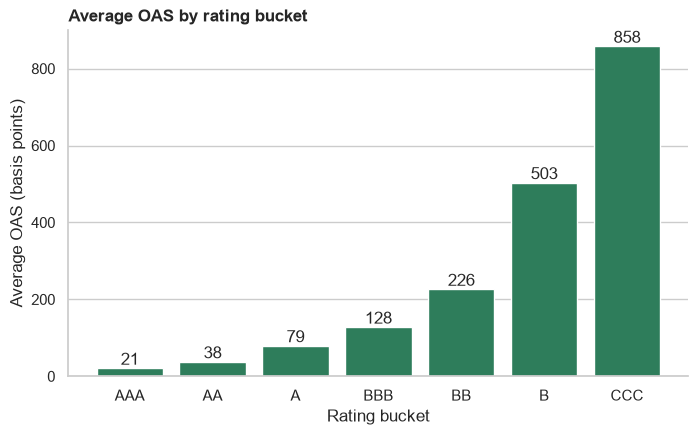

Saved: True


In [39]:
mean_by_bucket = book.groupby('bucket')['oas'].mean().loc[bucket_order]
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(mean_by_bucket.index, mean_by_bucket.values)
ax.bar_label(bars, fmt='%.0f')
desk_style(ax, 'Average OAS by rating bucket', 'Rating bucket', 'Average OAS (basis points)')
# savefig() before show(); the name's ending sets the type, dpi= the dots per inch,
# bbox_inches='tight' trims the margin
fig.savefig('average_oas_by_bucket.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved:', os.path.exists('average_oas_by_bucket.png'))
# remove it here, though in your own work you keep it; '.pdf' stays sharp at any size,
# and a seaborn grid saves the same way, with grid.figure.savefig()
os.remove('average_oas_by_bucket.png')

These are Visualization's bars, 21 bp at AAA to 858 at CCC, in the desk's look: one call styles any chart, and one edit restyles the pack.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Axis limits</td><td align="left"><code>ax.set_ylim(0, 600)</code></td><td align="left">Format Axis, Bounds, Minimum and Maximum</td></tr>
<tr><td align="left">Thousands separators</td><td align="left"><code>ax.yaxis.set_major_formatter('{x:,.0f}')</code></td><td align="left">Format Axis, Number, Format Code <code>#,##0</code></td></tr>
<tr><td align="left">A value on each bar</td><td align="left"><code>ax.bar_label(bars)</code></td><td align="left">Chart Elements, Data Labels</td></tr>
<tr><td align="left">Save as a picture</td><td align="left"><code>fig.savefig('name.png')</code></td><td align="left">right-click the chart, Save as Picture</td></tr>
</table>
<br clear="left">

**One function holds the look; one line writes the file.**

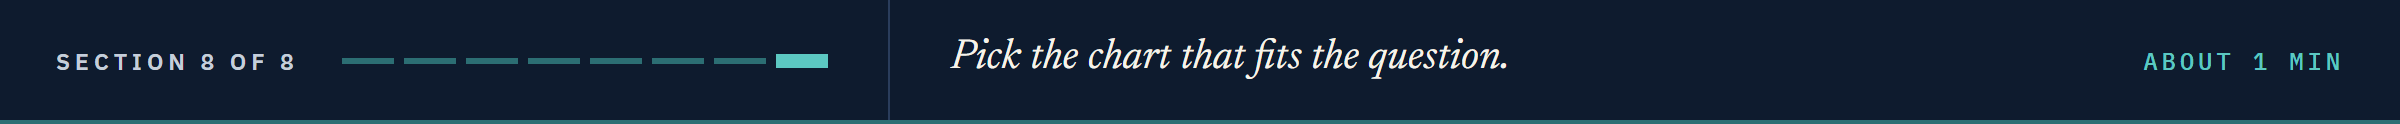

## 12.8 Choosing a Chart

The Visualization notebook's picture holds the first seven charts; today added these.

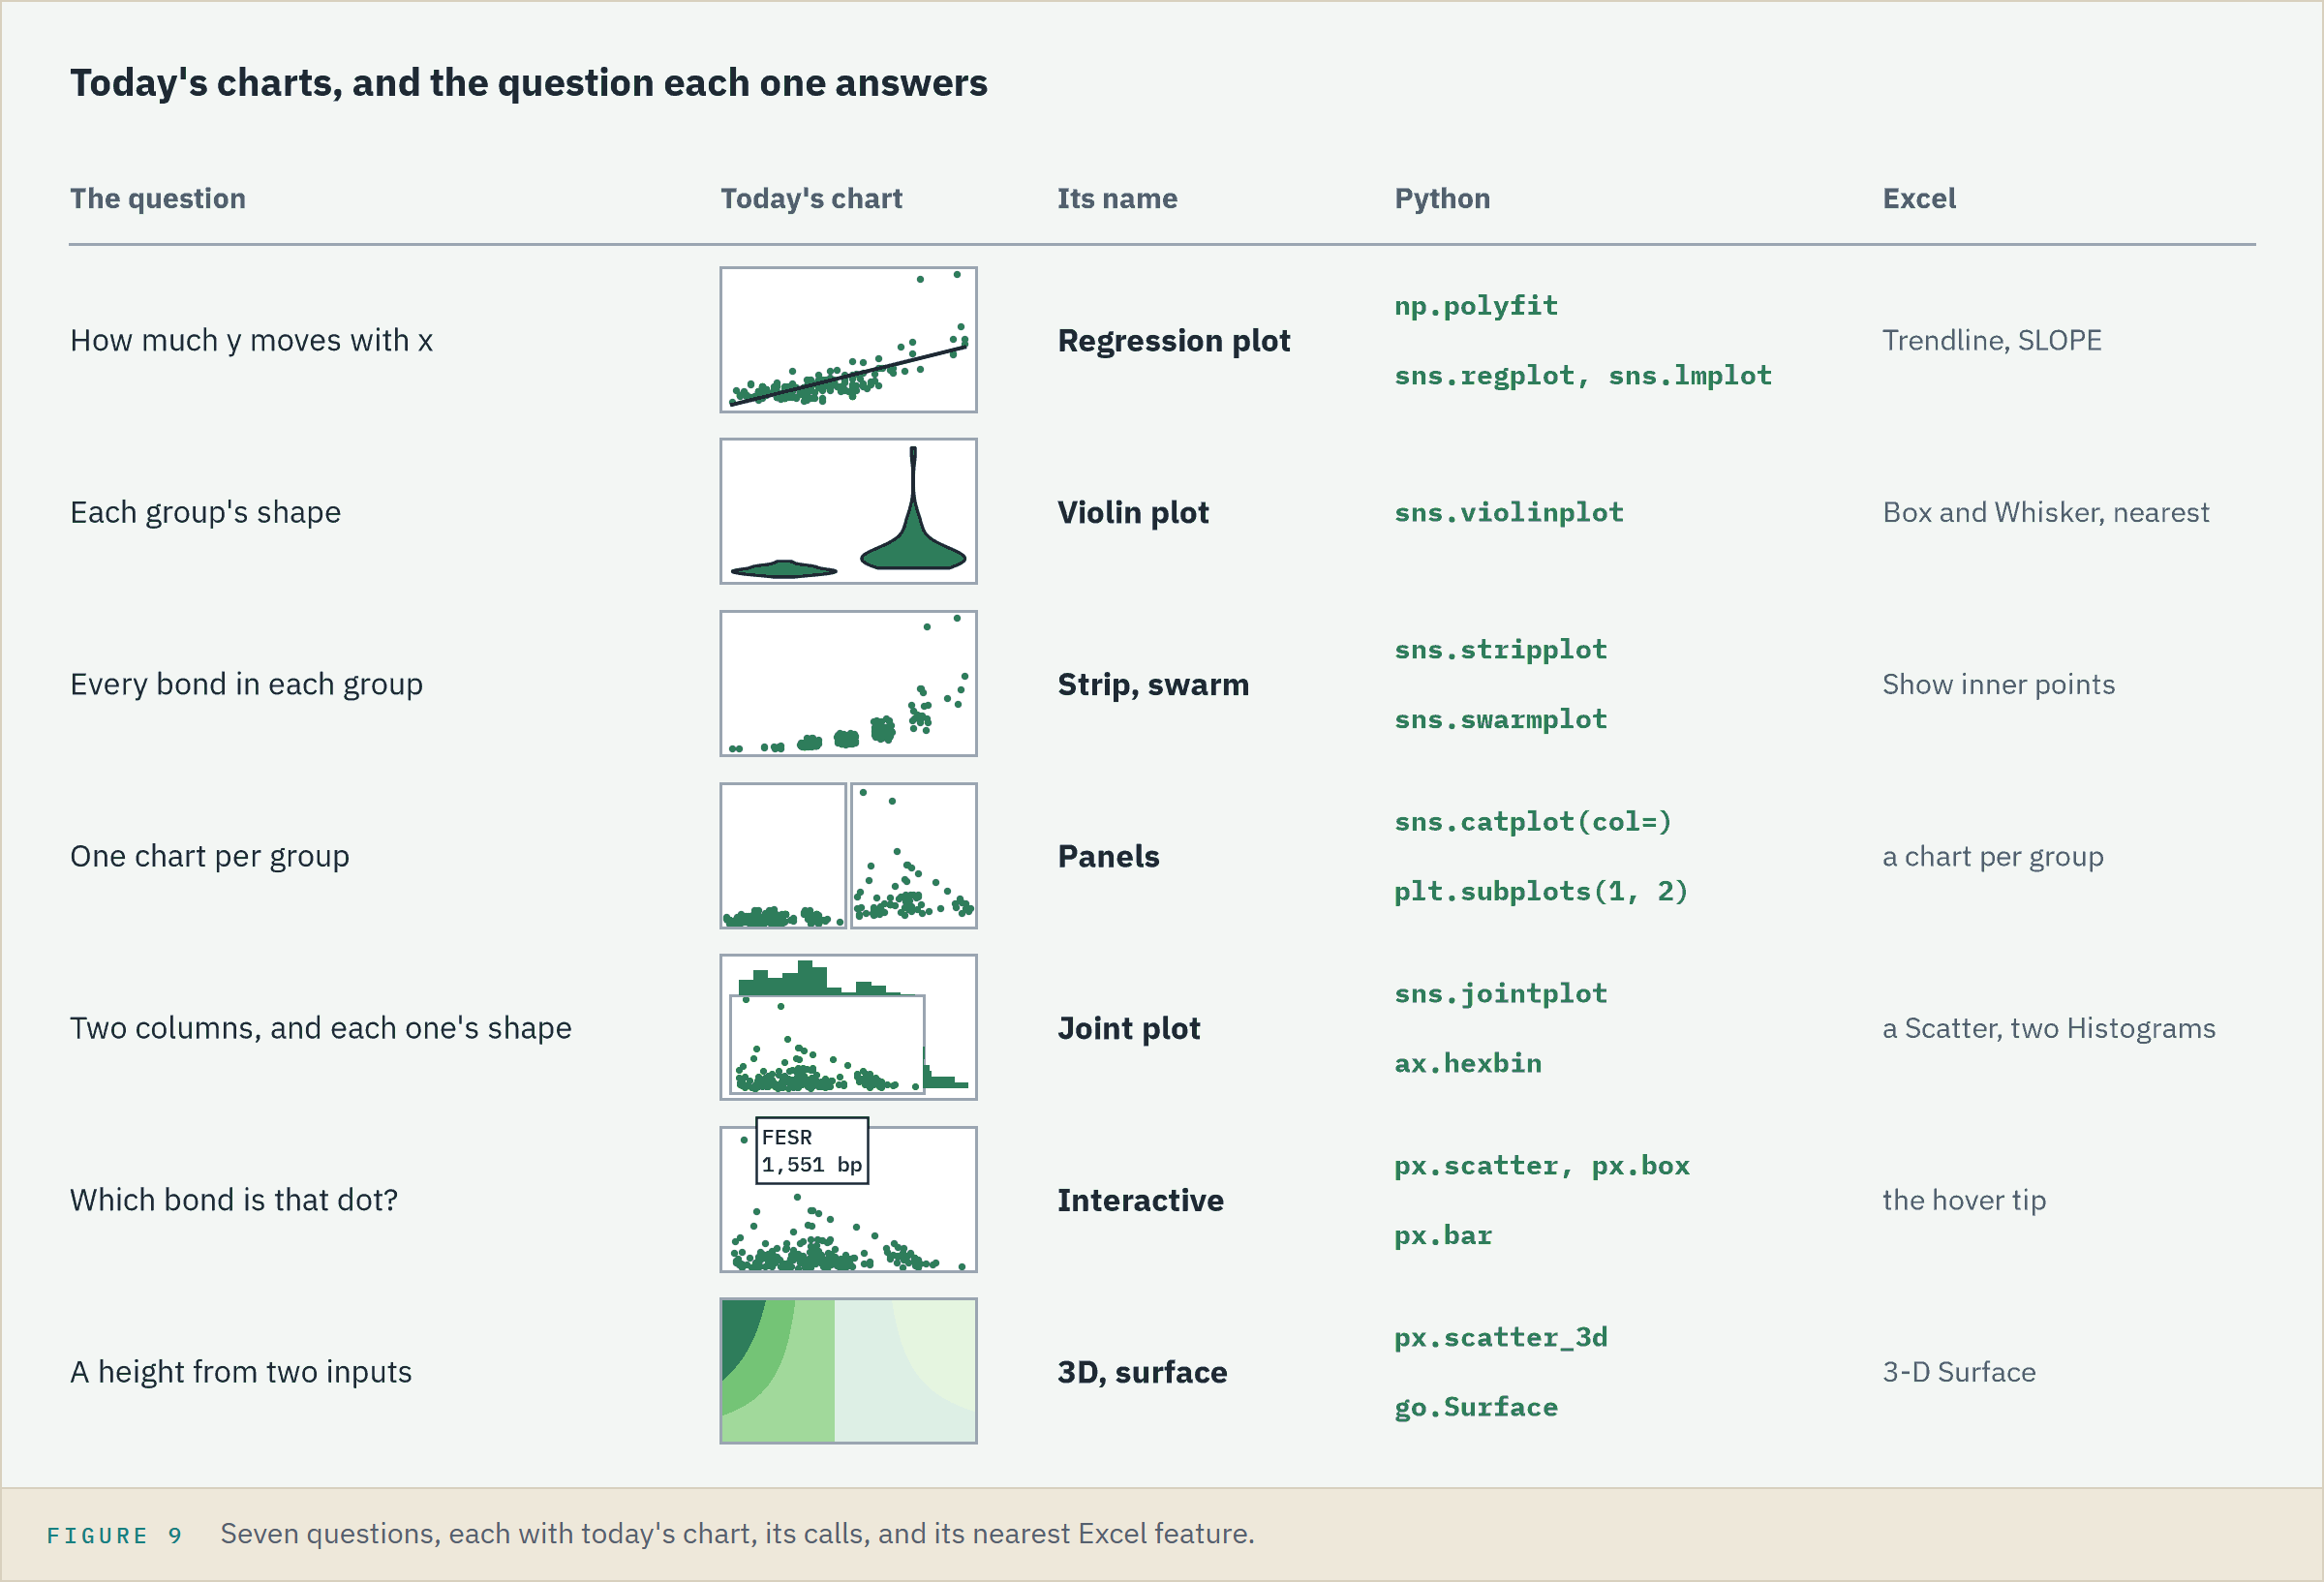

The habits of a chart that leaves the desk:

* Check a smoothed shape's ends against the data.
* Say what a narrowed axis left off, and start bars at zero.
* One unit per chart; back colour with a shape.

**Ask the question first, then pick the chart, then say on the chart what you did to the data.**

## You Can Now

By the end of this notebook, you can:

* Fit a line, give its slope, intercept, and R squared in units, and draw it with `regplot()` or `lmplot()`.
* Show each group's shape with a violin and every bond with a strip or swarm.
* Split a chart into panels with `catplot()`, and draw a joint plot.
* Draw a plotly chart, read a bond off it, and save it as a web page.
* Draw a 3D scatter and a surface, and say when 3D misleads.
* Finish a chart for a meeting, in one style, saved to a file.

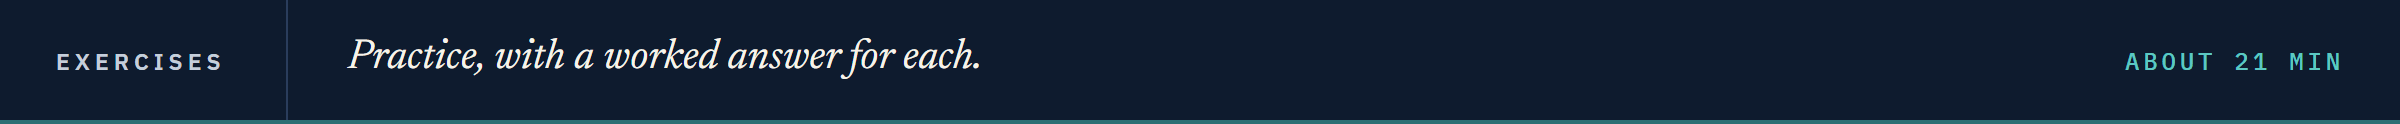

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: the first defines `check`, which marks your answers; the second reloads `book` and `bucket_order` in today's chart settings.

In [40]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [41]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# fresh copies of the two tables, in Colab from GitHub, and today's chart settings
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
book = pd.merge(holdings, ratings, on='rating')
bucket_order = ratings.sort_values('score')['bucket'].unique().tolist()
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'],
              rc={'boxplot.medianprops.color': '#1E4D3A'})
px.defaults.template = 'plotly_white'
px.defaults.color_discrete_sequence = ['#2E7D5B', '#9AA5B1']
print(book.shape)
print(bucket_order)

(200, 22)
['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC']


### Exercise 1

Q. `score` numbers the ratings from 1 (AAA) to 18 (CCC). Fit `oas` on `score` with `np.polyfit()` and draw it with `sns.regplot()`. Store the slope and intercept, to 2 places, in **ex1_slope** and **ex1_intercept**.

In [42]:
ex1_slope = ...
ex1_intercept = ...

In [43]:
check('Exercise 1 slope', ex1_slope, 42.45)
check('Exercise 1 intercept', ex1_intercept, -211.63)

Exercise 1 slope: not attempted yet
Exercise 1 intercept: not attempted yet


### Exercise 2

Q. Draw `price` as a strip plot by bucket, in credit order, after `np.random.seed(0)`. Store the lowest price in **ex2_low** and its bucket in **ex2_bucket**; `idxmin()` gives the row label of the smallest value.

In [44]:
ex2_low = ...
ex2_bucket = ...

In [45]:
check('Exercise 2 lowest price', ex2_low, 62.045)
check('Exercise 2 bucket', ex2_bucket, 'B')

Exercise 2 lowest price: not attempted yet
Exercise 2 bucket: not attempted yet


### Exercise 3

Q. Draw each sector's share of market value as flat bars, largest on top, with a percent axis and the value on each bar. Store the largest sector in **ex3_sector** and its share in percent, to 1 place, in **ex3_share**.

In [46]:
ex3_sector = ...
ex3_share = ...

In [47]:
check('Exercise 3 sector', ex3_sector, 'Materials')
check('Exercise 3 share', ex3_share, 14.6)

Exercise 3 sector: not attempted yet
Exercise 3 share: not attempted yet


### Exercise 4

Q. Draw a plotly scatter of `dts` against `duration` by grade, the issuer heading the hover box, ticker and rating inside. Point at the highest dot, then confirm with `idxmax()`: store its ticker in **ex4_ticker** and DTS in **ex4_dts**.

In [48]:
ex4_ticker = ...
ex4_dts = ...

In [49]:
check('Exercise 4 ticker', ex4_ticker, 'CLDB')
check('Exercise 4 DTS', ex4_dts, 6525.8)

Exercise 4 ticker: not attempted yet
Exercise 4 DTS: not attempted yet


### Exercise 5

Q. Write `fitted_line_chart(x_column, y_column, x_label, y_label)`: it draws the bonds with the fitted line, a title and both labels, and returns the slope to 2 places. Store its slope for `dts` on `duration` in **ex5_dts_slope** and for `price` on `coupon` in **ex5_price_slope**.

In [50]:
def fitted_line_chart(x_column, y_column, x_label, y_label):
    """Draw y_column against x_column for the 200 bonds, with the fitted line. Return the slope."""
    return ...


ex5_dts_slope = fitted_line_chart('duration', 'dts', 'Duration (years)',
                                  'DTS (duration times spread)')
ex5_price_slope = fitted_line_chart('coupon', 'price', 'Coupon (percent)',
                                    'Clean price (per 100 of face)')

In [51]:
check('Exercise 5 slope of DTS on duration', ex5_dts_slope, 127.52)
check('Exercise 5 slope of price on coupon', ex5_price_slope, 1.38)

Exercise 5 slope of DTS on duration: not attempted yet
Exercise 5 slope of price on coupon: not attempted yet


### Exercise 6

Q. Fit `yield_pct` on `coupon` for each grade on its own, and draw the grades in two panels with `sns.lmplot(col='grade', ci=None)`. Store the slopes, to 2 places, in **ex6_ig_slope** and **ex6_hy_slope**.

In [52]:
ex6_ig_slope = ...
ex6_hy_slope = ...

In [53]:
check('Exercise 6 Investment Grade slope', ex6_ig_slope, 0.2)
check('Exercise 6 High Yield slope', ex6_hy_slope, 1.11)

Exercise 6 Investment Grade slope: not attempted yet
Exercise 6 High Yield slope: not attempted yet


### Exercise 7: AI check

You ask an AI assistant to fit yield on coupon and draw the line over the bonds.

Its code, written for this course in an AI's style, has one bug.

Q. Before you run it: what slope should it find? Section 12.2 worked it out. Then run it, find the bug, and fix the cell so **ex7_slope** holds the fit of yield on coupon.

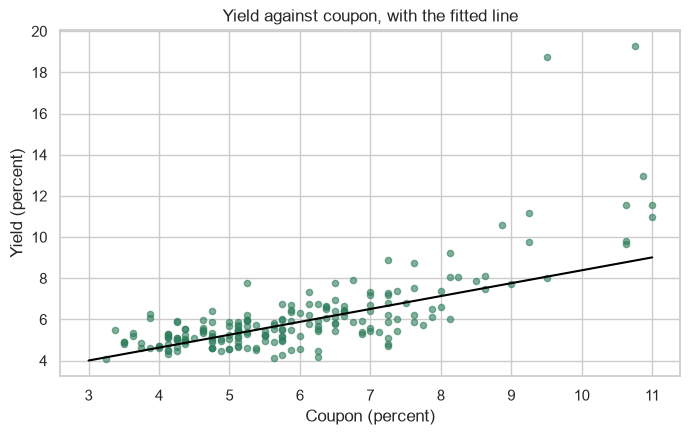

In [54]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# straight-line fit of yield on coupon
slope, intercept = np.polyfit(book['yield_pct'], book['coupon'], 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(book['coupon'], book['yield_pct'], s=20, alpha=0.6)

# the fitted line between a coupon of 3 percent and 11 percent
line_x = np.array([3, 11])
ax.plot(line_x, intercept + slope * line_x, color='black')

ax.set_title('Yield against coupon, with the fitted line')
ax.set_xlabel('Coupon (percent)')
ax.set_ylabel('Yield (percent)')

plt.show()

ex7_slope = round(slope, 2)

In [55]:
check('Exercise 7 slope', ex7_slope, 0.88)

Exercise 7 slope: not yet. You have 0.63


## Congratulations!

You made it through More Visualization.

The note is answered:

<table align="left">
<tr><th align="left">Asked</th><th align="left">Chart</th><th align="left">Answer</th></tr>
<tr><td align="left">A slope, in units</td><td align="left">regression plot</td><td align="left">0.88 points of yield per point of coupon, R squared 0.55</td></tr>
<tr><td align="left">The bonds behind the shapes</td><td align="left">strip plot</td><td align="left">2 bonds at AAA against 62 at BBB</td></tr>
<tr><td align="left">A chart fit to leave the desk</td><td align="left">the desk style, saved</td><td align="left">colours, honest axes, FESR marked, a file</td></tr>
</table>
<br clear="left">

Be proud: you caught 8 hidden bonds and a 2 percent gap drawn as 2.77 times.
Every chart today trusted the file; the next notebook opens one that should not be trusted and uses these charts to find what is wrong.

[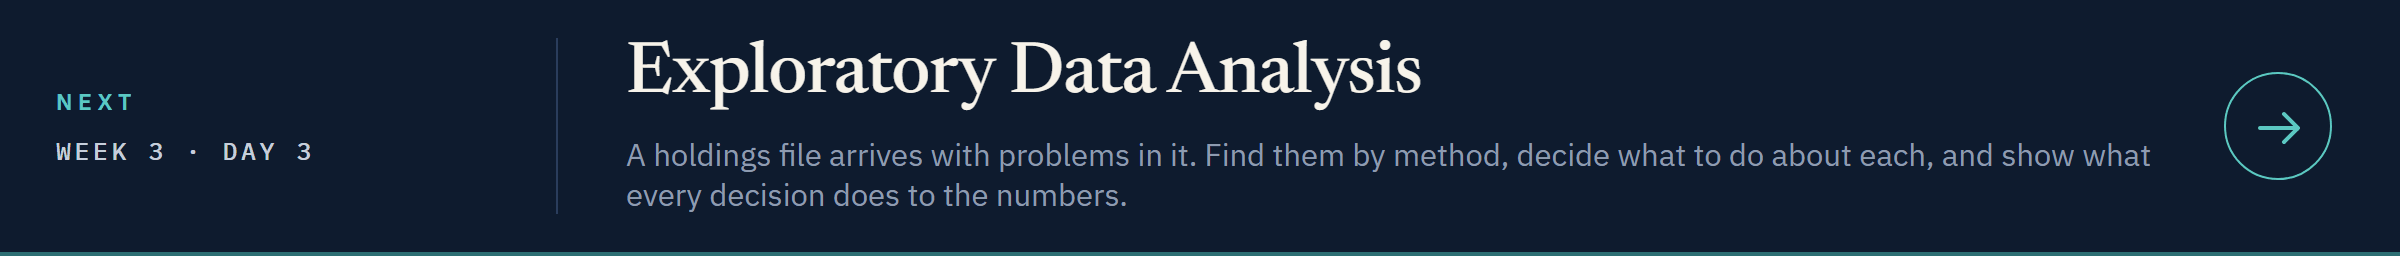](../day3/13_exploratory_data_analysis.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day3/13_exploratory_data_analysis.ipynb)